# GPtoy 学习实验室：从零理解遗传编程

这是一个围绕 **Koza-1 符号回归** 的系统化 GP 学习实验室。目标不是把 GP 调得更快或更强，
而是让你能回答下面五个问题，并能用**可复现的实验**支持自己的回答：

1. GP 的各个阶段分别执行了什么操作？
2. 每个阶段为什么需要这样的设计？
3. 结构、参数与随机性如何共同决定搜索过程？
4. GP 为什么有时成功、有时失败？
5. 怎样用对照实验区分不同类型的失败，并把现象变成可调研的研究问题？

## 学习方法：预测 → 运行 → 观察 → 解释

每个实验都按同一协议组织，请**先写预测再运行**：

| 步骤 | 你要做的事 |
|---|---|
| 1. 预测 | 在实验的 `我的预测（请填写）` 处写下你的判断与理由 |
| 2. 运行 | 直接运行代码单元；如需改动，修改单元顶部标出的参数后重跑 |
| 3. 观察 | 记录真实数字/图形，区分“看到了什么”和“我以为什么” |
| 4. 解释 | 写 `观察与解释（请填写）`：支持/反对证据、替代解释、证据边界 |

**本 Notebook 只提供可复现的实验与数据，不替你写研究结论。** 所有个人区域都是空占位。

## 环境与使用方法

- Python 3.12，依赖 `numpy`、`matplotlib`；Jupyter kernel 名为 **`gptoy`**；
- 所有算法在 `gptoy/` 包中从零实现，Notebook 只负责讲解、调用与可视化；
- 无网络、无 `input()`、无需手动点击；从头执行即可复现全部输出；
- 若图不显示：确认 kernel 是 `gptoy`，并检查单元 `%matplotlib inline` 已执行；
- 默认配置刻意很小（种群 20–100、代数 5–50），完整跑完通常几十秒；
  放大方法见文末 **附录 A**。

## 目录

- **第一篇：GP 的经典运行机制**
  - Chapter 0：GP 与符号回归（基线运行）
  - Chapter 1：表达式树与程序表示（E01）
  - Chapter 2：种群初始化（E02）
  - Chapter 3：适应度评价（E03）
  - Chapter 4：选择机制（E04）
  - Chapter 5：遗传操作（E05）
  - Chapter 6：完整进化过程（E06）
- **第二篇：GP 的典型失败**
  - Chapter 7：随机性与搜索预算（E07）
  - Chapter 8：早熟收敛与表达式膨胀（E08）
  - Chapter 9：小样本、噪声与泛化（E09）
  - Chapter 10：搜索空间与数值语义的限制（E10）
- **第三篇：从实验走向研究**
  - Chapter 11：GP 失败机制与改进方法（综合 E01–E10）
- **附录**：保存实验结果、放大实验规模、保存个人笔记、常见问题

## 记号与约定

| 记号 | 含义 |
|---|---|
| `mse_target = 1e-6` | “训练/测试数值达标”的阈值，**不是**“公式被严格恢复”的判据 |
| `best_fitness` | 当代最小适应度（本项目 MSE 越小越好） |
| `generation 0` | 初始种群这一代（尚未发生任何遗传操作） |
| `evaluations` | 为搜索而做的训练适应度评估次数（测试评价不计入） |
| 测试集 | 只用于最终评价；不参与选择、调参或挑选种子 |

## 科学诚实：四级证据标签

本 Notebook 的叙述尽量显式区分四类陈述，请你也用同样的标签写笔记：

- **观察**：本次运行实际打印/画出的数字与图形；
- **机制解释**：由对照实验支持的因果解释（说明控制了哪些变量）；
- **猜测**：尚未检验的推测，必须标注为猜测；
- **文献/数学事实**：来自外部知识或数学证明，须注明依据（如“sin 不是有理函数”）。

把数值拟合直接写成“严格恢复了公式”是本任务明确禁止的过度声明。

In [1]:
%matplotlib inline
# 环境检查与公共导入：所有实验都只通过 gptoy 包调用算法
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# 保证 notebook 在内核工作目录为仓库根目录或 notebooks/ 时都能 import gptoy
ROOT = Path.cwd()
if not (ROOT / "gptoy").is_dir() and (ROOT.parent / "gptoy").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import gptoy
from gptoy.config import GPConfig
from gptoy.data import koza1_target, make_koza1_data, make_target_data
from gptoy.evolution import EvolutionEngine, run_gp
from gptoy.experiments import (
    add_gaussian_noise,
    initialization_experiment,
    load_experiment,
    make_parsimony_fitness,
    make_train_val_test,
    run_budget_experiment,
    run_seed_batch,
    save_experiment,
    summarize_runs,
    tournament_experiment,
)
from gptoy.initialization import full as make_full, initial_population
from gptoy.metrics import complexity, population_stats, structural_signature
from gptoy.operators import evaluate, fitness, p_div
from gptoy.representation import Node, str_to_tree
from gptoy.selection import tournament_select
from gptoy.tracing import EvolutionTracer, GenerationSnapshot, GeneticEvent
from gptoy.utils import make_rng
from gptoy.variation import (
    apply_variation,
    apply_variation_traced,
    crossover,
    crossover_traced,
    mutate,
    mutate_traced,
    reproduce,
)
from gptoy.viz import draw_tree, plot_tree

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "font.size": 9})

print(f"Python      : {sys.version.split()[0]}")
print(f"numpy       : {np.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")
print(f"gptoy       : {gptoy.__file__}")
print(f"工作目录    : {Path.cwd()}")


def print_table(headers, rows):
    '''打印等宽文本表；按东亚字符显示宽度对齐（不引入额外依赖）。'''
    import unicodedata

    def width(text):
        return sum(2 if unicodedata.east_asian_width(ch) in ("W", "F") else 1
                   for ch in str(text))

    def pad(text, target):
        text = str(text)
        return text + " " * max(0, target - width(text))

    cells = [[str(h) for h in headers]] + [[str(v) for v in row] for row in rows]
    widths = [max(width(row[i]) for row in cells) for i in range(len(headers))]
    print("  ".join(pad(h, w) for h, w in zip(headers, widths)))
    print("  ".join("-" * w for w in widths))
    for row in rows:
        print("  ".join(pad(v, w) for v, w in zip(row, widths)))

Python      : 3.12.13
numpy       : 2.4.4
matplotlib  : 3.10.8
gptoy       : G:\CreateMyself\others\ReproducePaper\GP\.dsh-best-of-3\gptoy-lab-20261022-2e22987\candidates\a\gptoy\__init__.py
工作目录    : G:\CreateMyself\others\ReproducePaper\GP\.dsh-best-of-3\gptoy-lab-20261022-2e22987\candidates\a


# 第一篇：GP 的经典运行机制

*Chapter 0–6：从表示、初始化、评价、选择、变异到完整进化循环*

> 本部分包含：Chapter 0 GP 与符号回归、Chapter 1 表达式树与程序表示、Chapter 2 种群初始化、Chapter 3 适应度评价、Chapter 4 选择机制、Chapter 5 遗传操作、Chapter 6 完整进化过程

## Chapter 0：GP 与符号回归

**核心问题**：GP 在符号回归里到底搜索什么？训练/测试 MSE 很小，能说明公式被严格恢复了吗？

### 概念与数学定义

**符号回归**：给定有限个观测 $(x_i, y_i)$，在一个由函数集与终止符集递归生成的
表达式空间中寻找一个表达式 $T$，使 $T(x_i) \approx y_i$。与参数拟合不同，GP 同时搜索
**结构**（用哪些运算、怎样嵌套）与**数值行为**。

**搜索空间**：从终止符 $x$ 出发，反复用二元运算 $+,-,*,/$ 组合已有表达式，可得到全部
有限表达式树。本项目的目标 $f(x)=x^4+x^3+x^2+x$ 位于该空间内，因为

$$x^4+x^3+x^2+x = x(x+1)(x^2+1),$$

而常数 $1$ 可以用保护除法 $x/x$ 合成。注意：**“目标在空间内”不等于“有限预算内一定搜到”**。

**结构发现 vs 常数优化**：经典 GP 用随机常数或常数合成来近似系数；本项目的终止符只有
$x$，系数只能靠 $x/x=1$、$x-x=0$ 等组合“合成”，这让常数优化本身也成为结构搜索的一部分。

**Koza-1 完整定义**：

- 训练集：$[-1,1]$ 上等距 20 点，标签由 $f(x)=x^4+x^3+x^2+x$ 生成；
- 测试/泛化集：$[1,2]$ 上等距 10 点，标签同样由 $f$ 生成，但**从不参与搜索**；
- 预算：种群 100，最多 50 代；判定阈值 $\mathrm{MSE} < 10^{-6}$。

**三种“成功”必须分开**：

1. **数值拟合**：训练/测试 MSE 小；
2. **函数一致**：在关心的区间上逐点（或解析地）与目标一致；
3. **结构恢复**：得到的树与某个等价推导结构相同。

前两者可由有限样本上的数字支持，第三者需要结构判定或数学论证。本 Notebook 会反复展示
“数值上完全一致、结构却不同”的例子。

### 具体小例子

目标 $f(x)=x^4+x^3+x^2+x$ 可以写成因式分解形式 $x(x+1)(x^2+1)$。两种写法对应两棵
结构不同的树（展开树 19 个节点、深度 6；因式树 15 个节点、深度 5），但在所有输入上
函数值相同。**只看训练/测试 MSE，无法判断算法找到的是哪一种结构**——这正是“数值拟合”
与“结构恢复”的分界线。

### 源码入口

- 目标公式与数据：`gptoy/data.py` → `koza1_target`、`make_koza1_data`
- 适应度：`gptoy/operators.py` → `fitness`
- 主循环：`gptoy/evolution.py` → `run_gp`、`EvolutionEngine`

> **我的预测（请填写）**：在 seed=3、种群 100、最多 50 代的预算下，你认为第 0 代的
> best 训练 MSE 大概是什么量级？大约第几代能达标？最终表达式会不会与标准树
> `(+ (+ (+ (* (* x x) (* x x)) (* x (* x x))) (* x x)) x)` 结构相同？为什么？

In [2]:
# 运行 Koza-1 基线：默认配置 + 固定 seed=3（与旧教学案例一致）
SEED = 3
cfg = GPConfig(seed=SEED)
x_train, y_train, x_test, y_test = make_koza1_data(cfg)

baseline = run_gp(cfg)

print(f"训练集 {x_train.shape[0]} 点 @ [{cfg.train_lo}, {cfg.train_hi}]")
print(f"测试集 {x_test.shape[0]} 点 @ [{cfg.test_lo}, {cfg.test_hi}]")
print()
print_table(
    ["指标", "数值"],
    [
        ("第 0 代 best 训练 MSE", f"{baseline.gen0_mse:.6g}"),
        ("首次达标代数", baseline.generation_found),
        ("实际运行代数", baseline.n_generations),
        ("训练 MSE", f"{baseline.train_mse:.3e}"),
        ("测试 MSE", f"{baseline.test_mse:.3e}"),
        ("训练适应度评估次数", baseline.evaluations),
        ("运行耗时 (s)", f"{baseline.total_seconds:.2f}"),
    ],
)
print()
print("最终表达式（S-表达式）：")
print(" ", baseline.best_of_run.sexpr_str())
print("最终表达式（中缀）：")
print(" ", baseline.best_of_run.infix_str())
print(f"结构规模：size={baseline.best_of_run.size()}, depth={baseline.best_of_run.depth()}")

训练集 20 点 @ [-1.0, 1.0]
测试集 10 点 @ [1.0, 2.0]

指标                   数值     
---------------------  ---------
第 0 代 best 训练 MSE  0.0964771
首次达标代数           5        
实际运行代数           5        
训练 MSE               5.367e-32
测试 MSE               3.234e-30
训练适应度评估次数     600      
运行耗时 (s)           0.58     

最终表达式（S-表达式）：
  (* (+ (* x x) x) (* (* x (+ (+ (/ (/ x x) x) x) (* (- x x) (+ x x)))) (/ x x)))
最终表达式（中缀）：
  (((x * x) + x) * ((x * ((((x / x) / x) + x) + ((x - x) * (x + x)))) * (x / x)))
结构规模：size=27, depth=8


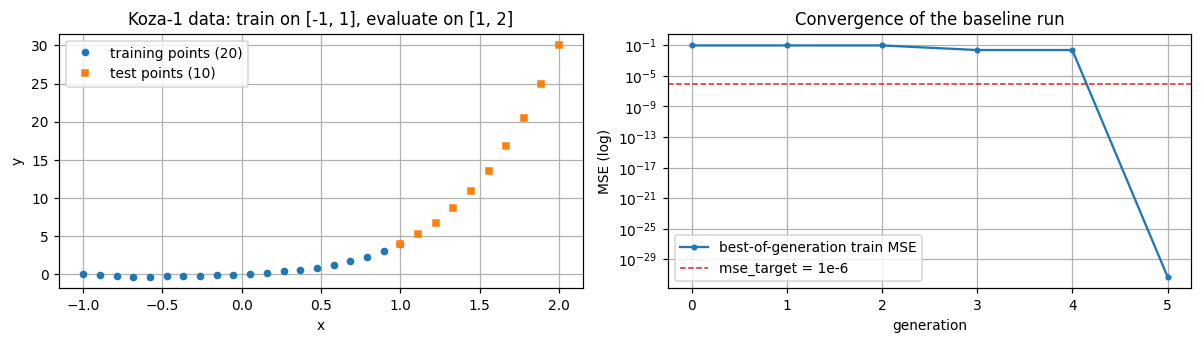

In [3]:
# 数据长什么样：训练区间与泛化区间是分开的
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))

axes[0].plot(x_train, y_train, "o", ms=4, label="training points (20)")
axes[0].plot(x_test, y_test, "s", ms=4, label="test points (10)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Koza-1 data: train on [-1, 1], evaluate on [1, 2]")
axes[0].legend()

axes[1].semilogy(baseline.best_mse_history, "-o", ms=3, label="best-of-generation train MSE")
axes[1].axhline(cfg.mse_target, color="tab:red", ls="--", lw=1, label="mse_target = 1e-6")
axes[1].set_xlabel("generation")
axes[1].set_ylabel("MSE (log)")
axes[1].set_title("Convergence of the baseline run")
axes[1].legend()
fig.tight_layout()

In [4]:
# 数值一致 ≠ 结构相同：把基线结果与“标准树”比较
canonical = str_to_tree(
    "(+ (+ (+ (* (* x x) (* x x)) (* x (* x x))) (* x x)) x)", cfg
)
grid = np.linspace(-2.0, 2.0, 401)
gap = np.max(np.abs(evaluate(baseline.best_of_run, grid) - evaluate(canonical, grid)))

print(f"结构与标准树相同？        {baseline.best_of_run == canonical}")
print(f"标准树 size/depth：       {canonical.size()} / {canonical.depth()}")
print(f"本次结果 size/depth：     {baseline.best_of_run.size()} / {baseline.best_of_run.depth()}")
print(f"在 [-2, 2] 的 401 个点上最大绝对差：{gap:.3e}")
print()
print("阅读提示：请记录“结构是否相同”和“最大绝对差是多少”，并思考：")
print("      这两个事实分别能支持什么、不能支持什么？请写到本章「观察与解释（请填写）」。")

结构与标准树相同？        False
标准树 size/depth：       19 / 6
本次结果 size/depth：     27 / 8
在 [-2, 2] 的 401 个点上最大绝对差：5.329e-15

阅读提示：请记录“结构是否相同”和“最大绝对差是多少”，并思考：
      这两个事实分别能支持什么、不能支持什么？请写到本章「观察与解释（请填写）」。


### 观察与解释（请填写）

> **观察与解释（请填写）**：记录你实际看到的数字（gen0 MSE、首达代、最终表达式与结构），
> 再回答：这次运行属于“数值拟合 / 函数一致 / 结构恢复”中的哪一级？你的证据是什么？
> 测试集在这里能排除“只插值了训练点”吗？它还能排除什么、不能排除什么？

**本章局限**：

- 测试集只有 10 个点，且与训练集来自同一个已知目标函数；“测试 MSE 小”只说明在这 10 点上一致；
- 基线运行只展示了一个种子，不能据此推断 GP 的平均成功率（Chapter 7 才讨论分布）；
- 本次固定的 `seed=3` 来自仓库原有的教学种子搜索（`scripts/find_seed.py`），该搜索**同时使用
  训练与测试表现筛选**种子，属于教学用的成功样本，不能视为无偏的泛化成功率；
- 本 Notebook 中所有“达标”只表示数值阈值，不表示严格的公式恢复。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 1：表达式树与程序表示

**核心问题**：一个 GP 个体怎样被表示？不同的树什么时候表示同一个函数？保护运算改变了什么语义？

### 概念与数学定义

**Function Set / Terminal Set**：本项目函数集为 $\{+,-,*,/\}$（全部二元），终止符集为
$\{x\}$。一棵表达式树是一棵有序二叉树：内部节点是函数，叶子是终止符。

**Genotype / Phenotype**：在经典树型 GP 中，基因型（被遗传操作修改的对象）与表现型
（被求值的程序）都是同一棵树——这是树型 GP 与基因表达式编程（GEP）等表示的区别。

**深度与规模**：

- `depth(T)`：单节点树深度为 1，否则为 $1+\max_i \text{depth}(T_i)$；
- `size(T)`：节点总数 $=1+\sum_i \text{size}(T_i)$；
- 满二叉树深度 $d$ 的节点数为 $2^d-1$：深度增长会让规模指数增长，这是后面“膨胀”问题的根源。

**语法 vs 语义**：S-表达式唯一确定结构（语法），但不同结构可以表示同一函数（语义）。
例如标准树 `(+ (+ (+ (* (* x x) (* x x)) (* x (* x x))) (* x x)) x)` 与因式分解写法
$x(x+1)(x^2+1)$ 的树结构完全不同，函数却处处相等。

**保护运算（Protected Operations）**：`p_div(a, b)` 在 $b=0$ 时返回 $1.0$，而不是
抛出异常或返回 NaN/Inf。这是 Koza 的经典约定，保证适应度可计算，但它**改变了数学语义**：

$$\frac{x-x}{x}\Big|_{x=0} \;\text{按保护除法} = \frac{0}{0}\to 1.0,\quad
\text{而“先约分得 }0\text{”只在 }x\neq 0\text{ 成立。}$$

因此不能把普通代数化简当作保护除法下的全域等价变换；Chapter 10 会系统展示这一点。

### 具体小例子

树 `(+ x (* x x))` 表示 $x+x^2$，深度 3、规模 5；在 $x=3$ 处值为 $3+9=12$。
若把左边的 `x` 替换成 `(* x x)`，得到 $(x^2)+(x^2)=2x^2$——这正是 `replace_subtree` 做的事。

### 源码入口

- 树结构、路径访问、解析与显示：`gptoy/representation.py` → `Node`、`Node.iter_nodes`、
  `Node.subtree_at`、`Node.replace_subtree`、`str_to_tree`
- 递归求值与保护除法：`gptoy/operators.py` → `evaluate`、`p_div`
- 树绘制：`gptoy/viz.py` → `draw_tree`、`plot_tree`

### E01：构建、修改与比较表达式树

**研究问题**：结构不同的两棵树能否表示同一函数？在保护除法下，哪些“显然”的代数变换会失效？

**核心概念**：语法结构、函数语义、保护除法、结构相等 vs 数值相等。

**可修改配置**（直接改下面单元里的变量后重跑）：

- `TREE_A` / `TREE_B`：两棵要比较的 S-表达式；
- `PROBE_POINTS`：手工检查的输入点。

**运行入口**：下一代码单元（`# E01`）。

**源码位置**：`gptoy/representation.py`、`gptoy/operators.py`、`gptoy/viz.py`。

> **我的预测（请填写）**：先读下面两棵树的表达式，猜一猜 `TREE_A == TREE_B` 是 True 还是
> False？它们的函数值在 $[-2,2]$ 上会差多少？`(x^2-1)/(x-1)` 在 $x=1$ 处会得到什么？

In [5]:
# E01 结构 vs 语义：不同结构，同一函数
TREE_A = "(+ (+ (+ (* (* x x) (* x x)) (* x (* x x))) (* x x)) x)"  # 标准展开 x^4+x^3+x^2+x
TREE_B = "(* (* x (+ x (/ x x))) (+ (* x x) (/ x x)))"             # 因式分解 x(x+1)(x^2+1)

tree_a = str_to_tree(TREE_A, cfg)
tree_b = str_to_tree(TREE_B, cfg)
PROBE_POINTS = np.array([-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0])

print("tree_a:", tree_a.sexpr_str())
print("tree_b:", tree_b.sexpr_str())
print_table(
    ["树", "size", "depth", "结构相等(a==b)", "hash 相等"],
    [
        ("A", tree_a.size(), tree_a.depth(), tree_a == tree_b, hash(tree_a) == hash(tree_b)),
        ("B", tree_b.size(), tree_b.depth(), "-", "-"),
    ],
)
print()
print_table(
    ["x", "A(x)", "B(x)", "A(x)-B(x)"],
    [(f"{v:g}", f"{evaluate(tree_a, v):.12g}", f"{evaluate(tree_b, v):.12g}",
      f"{evaluate(tree_a, v) - evaluate(tree_b, v):.3e}") for v in PROBE_POINTS],
)
dense = np.linspace(-2.0, 2.0, 401)
print(f"\n更密网格上的最大绝对差：{np.max(np.abs(evaluate(tree_a, dense) - evaluate(tree_b, dense))):.3e}")
print("阅读提示：比较两棵树的 size/depth 与逐点数值；结构不同是否等于函数不同？")
print("      请把判断与理由写到本节「观察与解释（请填写）」。")

tree_a: (+ (+ (+ (* (* x x) (* x x)) (* x (* x x))) (* x x)) x)
tree_b: (* (* x (+ x (/ x x))) (+ (* x x) (/ x x)))
树  size  depth  结构相等(a==b)  hash 相等
--  ----  -----  --------------  ---------
A   19    6      False           False    
B   15    5      -               -        

x     A(x)     B(x)     A(x)-B(x)
----  -------  -------  ---------
-2    10       10       0.000e+00
-1    0        -0       0.000e+00
-0.5  -0.3125  -0.3125  0.000e+00
0     0        0        0.000e+00
0.5   0.9375   0.9375   0.000e+00
1     4        4        0.000e+00
2     30       30       0.000e+00

更密网格上的最大绝对差：7.105e-15
阅读提示：比较两棵树的 size/depth 与逐点数值；结构不同是否等于函数不同？
      请把判断与理由写到本节「观察与解释（请填写）」。


In [6]:
# E01 保护除法：形式代数变换在分母为 0 处失效
t_ratio = str_to_tree("(/ (- (* x x) (/ x x)) (- x (/ x x)))", cfg)  # (x^2-1)/(x-1)
t_zero_over_x = str_to_tree("(/ (- x x) x)", cfg)                    # (x-x)/x

print("(x^2-1)/(x-1) 用保护除法求值，与 x+1 比较：")
print_table(
    ["x", "保护除法结果", "x+1", "是否一致"],
    [(f"{v:g}", f"{evaluate(t_ratio, v):.6g}", f"{v + 1:.6g}",
      "是" if abs(evaluate(t_ratio, v) - (v + 1)) < 1e-9 else "否")
     for v in (-1.0, 0.5, 1.0, 2.0)],
)
print()
print(f"(x-x)/x 在 x=0 处：{evaluate(t_zero_over_x, 0.0):.1f}（按“先约分”会预期 0）")
print(f"x/x     在 x=0 处：{evaluate(str_to_tree('(/ x x)', cfg), 0.0):.1f}")
print("原因：分母精确为 0 时 p_div 直接返回 1.0，不执行 a/b。")

(x^2-1)/(x-1) 用保护除法求值，与 x+1 比较：
x    保护除法结果  x+1  是否一致
---  ------------  ---  --------
-1   -0            0    是      
0.5  1.5           1.5  是      
1    1             2    否      
2    3             3    是      

(x-x)/x 在 x=0 处：1.0（按“先约分”会预期 0）
x/x     在 x=0 处：1.0
原因：分母精确为 0 时 p_div 直接返回 1.0，不执行 a/b。


修改前 tree_b : (* (* x (+ x (/ x x))) (+ (* x x) (/ x x)))
修改后 modified: (* (* x x) (+ (* x x) (/ x x)))
tree_b 是否被改动？ True


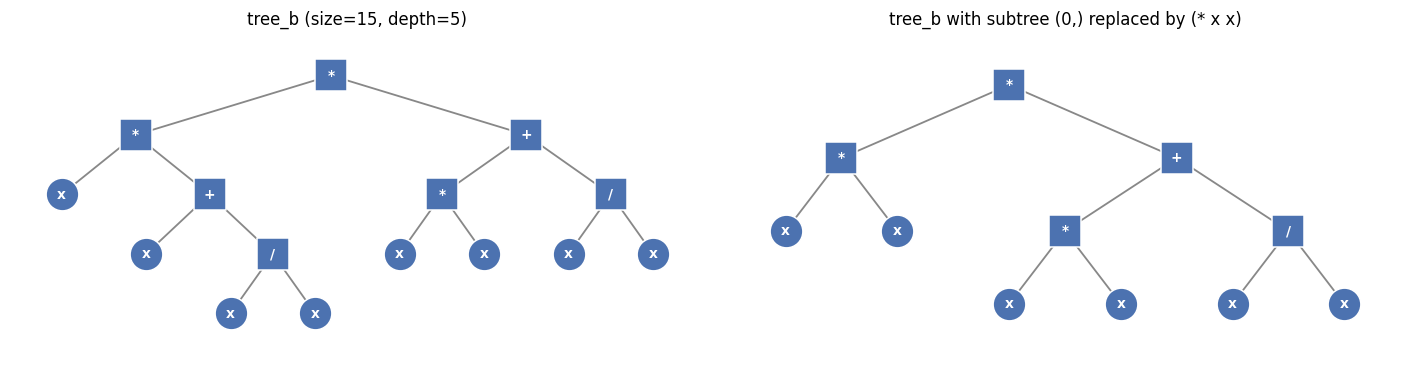

In [7]:
# E01 修改树：replace_subtree 返回新树，原树保持不变
modified = tree_b.replace_subtree((0,), str_to_tree("(* x x)", cfg))
print("修改前 tree_b :", tree_b.sexpr_str())
print("修改后 modified:", modified.sexpr_str())
print("tree_b 是否被改动？", tree_b.sexpr_str() == TREE_B)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
draw_tree(axes[0], tree_b, title=f"tree_b (size={tree_b.size()}, depth={tree_b.depth()})")
draw_tree(axes[1], modified, title="tree_b with subtree (0,) replaced by (* x x)")
fig.tight_layout()

### 观察与解释（请填写）

> **观察与解释（请填写）**：两棵树的 size/depth 差多少？数值差是多少？这个差是 0 吗，
> 还是只是浮点误差？`(x^2-1)/(x-1)` 在 $x=1$ 处偏离 $x+1$ 多少？
> 由此说明：为什么“结构相同”与“函数相同”必须分开讨论？

**本章局限**：这里的“函数相同”是在有限网格上数值验证的（`[-2,2]` 的 401 个点）；
严格的函数相等需要数学论证。保护除法只在分母精确为 0 时替换，接近 0 的分母仍会放大误差；
这些语义细节会直接影响“等价变换”是否成立。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 2：种群初始化

**核心问题**：初始种群怎样生成？full / grow / ramped half-and-half 会带来怎样的搜索起点与偏差？

### 概念与数学定义

设初始化深度参数为 $d$（本项目 `min_init_depth=2`、`max_init_depth=6`）。

- **Full**：所有叶子都在第 $d$ 层，是一棵满二叉树，节点数固定为 $2^d-1$；
- **Grow**：根强制为函数节点；其余节点从“函数集 ∪ 终止符集”中均匀抽取，
  抽到终止符就停止生长，因此深度 $\le d$ 且形状可变；
- **Ramped half-and-half**：对每个深度桶 $d\in[2,6]$ 生成一批个体，桶内一半 full、一半 grow，
  最后打乱顺序。它同时提供“深度多样性”和“形状多样性”。

**初始化偏差**：不同方法的深度分布、规模分布、结构唯一比例不同。Full 在固定深度上
形状单一；Grow 的深浅偏置由「终止符在抽样池中的比例」决定——本项目是 4 个函数 + 1 个
终止符，每个内部节点提前停止生长（抽到 x）的概率只有 $1/5$，所以 Grow 仍以接近最大深度
为主，平均只比 Full 略浅；若终止符比例更高，Grow 才会明显偏向浅树。Ramped 覆盖多个
深度桶。初始分布会影响后续选择和变异能接触到哪些结构，但**不能仅凭初始分布断言最终进化
一定更好**——那需要对照实验（Chapter 8）。E02 会直接检验这三种方法在你机器上的实际分布。

### 具体小例子

$d=5$ 时：full 树固定 31 个节点、深度 5；grow 树每个内部节点都在“继续生长”与“抽到 x
停止”之间选择，由于只有 1 个终止符、4 个函数，多数树仍会长到接近深度 5，只有少数提前
停止（例如根的两个子节点都抽到 x 时得到 3 个节点的浅树）。用同一随机种子生成同一个
种群，可以逐位复现；E02 的深度直方图会让你看到这一偏置的实际大小。

### 源码入口

- `gptoy/initialization.py` → `full`、`grow`、`initial_population`、`INIT_METHODS`
- 统计指标：`gptoy/metrics.py` → `population_stats`（深度/规模直方图、结构唯一比例）

### E02：三种初始化策略的搜索起点

**研究问题**：在相同种群规模与深度参数下，full / grow / ramped 生成的种群在深度分布、
规模分布与结构多样性上有什么差异？这些差异意味着怎样的搜索起点？

**核心概念**：初始化分布、深度桶、结构唯一比例。

**可修改配置**（改下面单元顶部的 `E02_DEPTH`、`E02_POP_SIZE`、`E02_METHODS` 后重跑）：

- `E02_DEPTH`：初始化深度上限；
- `E02_POP_SIZE`：种群规模；
- `E02_METHODS`：要比较的方法元组。

**运行入口**：下一代码单元（`# E02`）。

**源码位置**：`gptoy/initialization.py`、`gptoy/metrics.py`、`gptoy/experiments.py`
→ `initialization_experiment`。

> **我的预测（请填写）**：三种方法的平均深度、最大深度、平均节点数、结构唯一比例
> 大概会怎样排序？full 的深度直方图会是什么形状？ramped 呢？

In [8]:
# E02 三种初始化方法：深度/规模分布与结构唯一性
E02_DEPTH = 5
E02_POP_SIZE = 60
E02_METHODS = ("full", "grow", "ramped")

init_rows = initialization_experiment(
    cfg, E02_METHODS, depth=E02_DEPTH, population_size=E02_POP_SIZE, seed=0
)
print_table(
    ["method", "mean_depth", "max_depth", "mean_size", "max_size", "unique", "unique_ratio"],
    [
        (row["method"], f"{row['mean_depth']:.2f}", row["max_depth"],
         f"{row['mean_size']:.2f}", row["max_size"], row["unique_structures"],
         f"{row['unique_ratio']:.3f}")
        for row in init_rows
    ],
)
print()
for row in init_rows:
    print(f"{row['method']:>7} 深度直方图: {row['depth_histogram']}")
    print(f"{'':>7} 规模直方图: {dict(sorted(row['size_histogram'].items()))}")

method  mean_depth  max_depth  mean_size  max_size  unique  unique_ratio
------  ----------  ---------  ---------  --------  ------  ------------
full    5.00        5          31.00      31        60      1.000       
grow    4.83        5          20.03      31        59      0.983       
ramped  3.48        5          12.93      31        48      0.800       

   full 深度直方图: {5: 60}
        规模直方图: {31: 60}
   grow 深度直方图: {2: 3, 4: 1, 5: 56}
        规模直方图: {3: 3, 11: 7, 13: 1, 15: 6, 17: 8, 19: 6, 21: 2, 23: 7, 25: 5, 27: 5, 29: 5, 31: 5}
 ramped 深度直方图: {2: 15, 3: 15, 4: 16, 5: 14}
        规模直方图: {3: 15, 5: 4, 7: 12, 11: 1, 13: 3, 15: 11, 25: 1, 27: 4, 31: 9}


唯一比例： {'full': 1.0, 'grow': 0.983, 'ramped': 0.8}


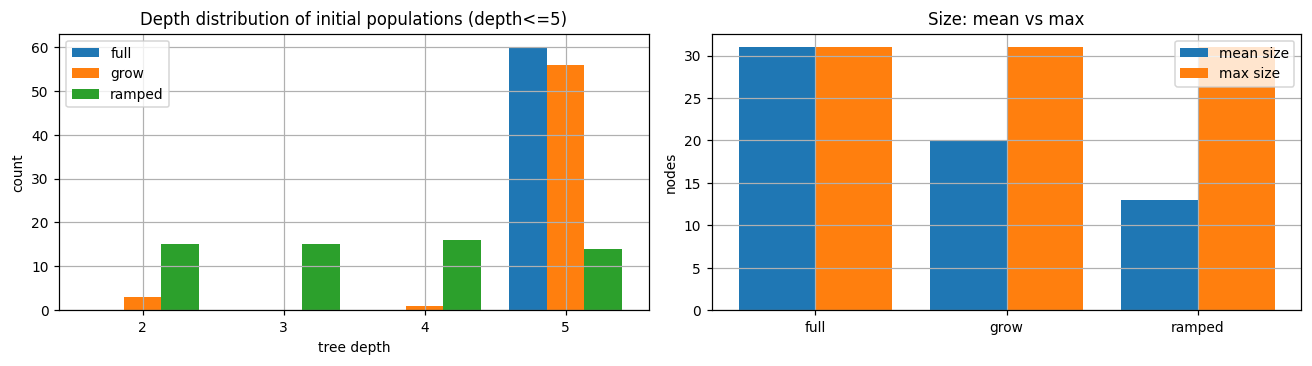

In [9]:
# E02 可视化：深度分布 + 规模/唯一性对比
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))

all_depths = sorted({d for row in init_rows for d in row["depth_histogram"]})
width = 0.8 / len(init_rows)
for i, row in enumerate(init_rows):
    heights = [row["depth_histogram"].get(d, 0) for d in all_depths]
    axes[0].bar([d + (i - (len(init_rows) - 1) / 2) * width for d in all_depths],
                heights, width=width, label=row["method"])
axes[0].set_xlabel("tree depth")
axes[0].set_ylabel("count")
axes[0].set_title(f"Depth distribution of initial populations (depth<={E02_DEPTH})")
axes[0].set_xticks(all_depths)
axes[0].legend()

xpos = np.arange(len(init_rows))
axes[1].bar(xpos - 0.2, [row["mean_size"] for row in init_rows], width=0.4, label="mean size")
axes[1].bar(xpos + 0.2, [row["max_size"] for row in init_rows], width=0.4, label="max size")
axes[1].set_xticks(xpos)
axes[1].set_xticklabels([row["method"] for row in init_rows])
axes[1].set_ylabel("nodes")
axes[1].set_title("Size: mean vs max")
axes[1].legend()

fig.tight_layout()
print("唯一比例：", {row["method"]: round(row["unique_ratio"], 3) for row in init_rows})

### 观察与解释（请填写）

> **观察与解释（请填写）**：三种方法的平均深度和规模差多少？哪一种的深度分布最集中？
> ramped 是否覆盖了多个深度桶？结构唯一比例说明什么？如果只改变深度上限或种群规模，
> 这些结论会变吗？请记录你实际改参数后的结果。

**本章局限**：这里只观察初始化后的**起点**，没有让它们各自进化。初始化分布与最终搜索
成败之间没有必然的单向关系；要判断哪种起点更好，必须进入同一预算下的对照实验。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 3：适应度评价

**核心问题**：适应度怎样定义？MSE 能评价什么、不能评价什么？训练/验证/测试各自负责什么？

### 概念与数学定义

**经验风险（MSE）**：

$$\mathrm{MSE}(T; D)=\frac{1}{|D|}\sum_{(x,y)\in D}\big(T(x)-y\big)^2 .$$

本项目用训练集 MSE 作为唯一搜索信号：`fit = fitness(tree, x_train, y_train)`。
`fitness` 只接收 `(tree, x, y)`，内部不出现目标公式；这是“从零实现 GP”的硬约束。

**复杂度**：`size(T)` 与 `depth(T)`。MSE 与复杂度是两个不同维度：同样小的 MSE 可以来自
很小或很大的树；同样复杂度的树可以有很不同的误差。

**三个数据集的职责**：

| 数据集 | 用途 | 能否反馈到搜索 |
|---|---|---|
| 训练集 | 计算适应度、驱动选择 | 能，唯一允许的搜索信号 |
| 验证集 | 调参/模型选择（如选择 penalty、判断过拟合） | 只能用于事先声明的选择规则 |
| 测试集 | 最终评价、报告泛化 | **不能**；不能用来挑种子或调参 |

**为什么 MSE 不足以评价“公式恢复”**：

1. **欠定**：训练点太少时，多个不同结构可以有相同（甚至 0）训练误差；
2. **等价类**：同一函数有无限多种表达式结构；
3. **外推**：训练区间上一致，不代表区间外一致；
4. **有限样本噪声**：小 MSE 可能只是拟合了噪声。

### 具体小例子

取目标 $f(x)=x^2$，训练点 $x\in\{-1,0,1\}$。$T_1=x^2$、$T_2=x^4$、$T_3=x^6$ 在
这三个点上都给出 $(1,0,1)$，训练 MSE 全为 0；但在 $x=2$ 处分别给出 $4,16,64$。
**训练误差完全相同，三个表达式却是不同的函数。**

### 源码入口

- 适应度与求值：`gptoy/operators.py` → `fitness`、`evaluate`
- 复杂度：`gptoy/metrics.py` → `complexity`
- 数据：`gptoy/data.py` → `make_koza1_data`、`make_target_data`

### E03：MSE 能区分什么、不能区分什么

**研究问题**：结构不同但数学等价的表达式，MSE 是否相同？训练误差相同（甚至为 0）的
候选，在独立测试点上的表现是否相同？

**核心概念**：经验风险、等价类、欠定问题、外推、训练/测试职责。

**可修改配置**（改下面单元顶部的 `KOZA_CANDIDATES` / `SMALL_TRAIN_X` 后重跑）：

- `KOZA_CANDIDATES`：在 Koza-1 训练/测试集上比较的若干候选结构；
- `SMALL_TRAIN_X`：欠定实验的训练点（默认三个点）。

**运行入口**：接下来两个代码单元（`# E03`）。

**源码位置**：`gptoy/operators.py` → `fitness`；`gptoy/data.py`。

> **我的预测（请填写）**：三个候选里，哪些训练 MSE 接近 0？它们的测试 MSE 会一样吗？
> 在三点训练集上，$x^2$、$x^4$、$x^6$ 的训练/测试 MSE 各是多少？

In [10]:
# E03-A 在 Koza-1 数据上比较三个结构
KOZA_CANDIDATES = {
    "exact": "(+ (+ (+ (* (* x x) (* x x)) (* x (* x x))) (* x x)) x)",
    "factored": "(* (* x (+ x (/ x x))) (+ (* x x) (/ x x)))",
    "partial_missing_x": "(+ (+ (* (* x x) (* x x)) (* x (* x x))) (* x x))",
}
print_table(
    ["候选", "训练 MSE", "测试 MSE", "size", "depth"],
    [
        (name,
         f"{fitness(str_to_tree(s, cfg), x_train, y_train):.6g}",
         f"{fitness(str_to_tree(s, cfg), x_test, y_test):.6g}",
         str_to_tree(s, cfg).size(), str_to_tree(s, cfg).depth())
        for name, s in KOZA_CANDIDATES.items()
    ],
)
print()
print("阅读提示：对比 exact / factored / partial_missing_x 的训练 MSE、测试 MSE 与结构。")
print("      仅凭这些数字，你能区分“数值拟合”与“结构恢复”吗？请写下你的依据。")

候选               训练 MSE     测试 MSE     size  depth
-----------------  -----------  -----------  ----  -----
exact              1.04771e-32  0            19    6    
factored           1.18661e-32  2.60324e-30  15    5    
partial_missing_x  0.368421     2.35185      17    5    

阅读提示：对比 exact / factored / partial_missing_x 的训练 MSE、测试 MSE 与结构。
      仅凭这些数字，你能区分“数值拟合”与“结构恢复”吗？请写下你的依据。


候选  训练 MSE（3 点）  独立测试 MSE  size
----  ----------------  ------------  ----
x^2   0                 0             3   
x^4   0                 50.6          7   
x^6   0                 1.23e+03      11  


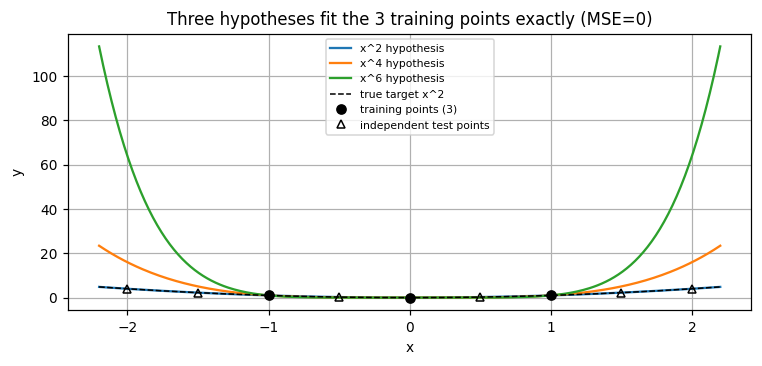

In [11]:
# E03-B 欠定训练集：三个不同结构有相同的 0 训练误差，测试表现却不同
SMALL_TRAIN_X = np.array([-1.0, 0.0, 1.0])
SMALL_TRAIN_Y = SMALL_TRAIN_X ** 2
PROBE_X = np.array([-2.0, -1.5, -0.5, 0.5, 1.5, 2.0])

hypotheses = {"x^2": "(* x x)", "x^4": "(* (* x x) (* x x))",
              "x^6": "(* (* x x) (* (* x x) (* x x)))"}
print_table(
    ["候选", "训练 MSE（3 点）", "独立测试 MSE", "size"],
    [
        (name,
         f"{np.mean((evaluate(str_to_tree(s, cfg), SMALL_TRAIN_X) - SMALL_TRAIN_Y) ** 2):.3g}",
         f"{np.mean((evaluate(str_to_tree(s, cfg), PROBE_X) - PROBE_X ** 2) ** 2):.3g}",
         str_to_tree(s, cfg).size())
        for name, s in hypotheses.items()
    ],
)

fig, ax = plt.subplots(figsize=(7, 3.4))
xs = np.linspace(-2.2, 2.2, 300)
for name, s in hypotheses.items():
    ax.plot(xs, evaluate(str_to_tree(s, cfg), xs), label=f"{name} hypothesis")
ax.plot(xs, xs ** 2, "k--", lw=1, label="true target x^2")
ax.plot(SMALL_TRAIN_X, SMALL_TRAIN_Y, "ko", ms=6, label="training points (3)")
ax.plot(PROBE_X, PROBE_X ** 2, "k^", ms=5, mfc="none", label="independent test points")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Three hypotheses fit the 3 training points exactly (MSE=0)")
ax.legend(fontsize=7)
fig.tight_layout()

### 观察与解释（请填写）

> **观察与解释（请填写）**：三个假设的训练 MSE 是否完全相同？测试 MSE 相差多少量级？
> 如果你只知道训练 MSE，能否从中挑出“正确”的 $x^2$？需要什么额外信息才能做到
> （更多训练点？区间先验？结构复杂度偏好？独立验证集？）请写下你的推理与证据边界。

**本章局限与诚实性说明**：

- 三点训练集是**刻意构造的说明性例子**，用来展示欠定问题，不代表典型 GP 运行；
- 独立测试点也来自同一个 $x^2$ 目标，但位于训练区间之外，因此度量的是外推；
- 在真实问题中，“测试 MSE 小”依然不能单独证明结构恢复，只能提供有限样本上的证据。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 4：选择机制

**核心问题**：选择压力从哪里来？锦标赛规模 k 改变了什么？“选择更强”是否等于“最终进化更好”？

### 概念与数学定义

**适应度比例选择**会按 $p_i \propto 1/\mathrm{MSE}_i$ 抽样，但要求适应度非负、对异常值敏感。
本项目使用**锦标赛选择**：每轮有放回地随机抽取 $k$ 个个体，取 $\mathrm{MSE}$ 最小者作为父本；
重复直到凑够所需父本数。

设种群规模为 $N$，且只有一个全局最优个体。一次锦标赛没有抽到它的概率是 $(1-1/N)^k$，
所以它被选中的概率是

$$P_{\text{best}}(k)=1-\left(1-\frac{1}{N}\right)^k .$$

$k=1$ 时 $P=1/N$（纯随机抽样）；$k$ 增大时 $P$ 迅速接近 1。**选择压力**就是这种“更优者
更容易成为父本”的倾向。

**有放回**意味着同一个亲本可以多次被选中，种群多样性可能迅速下降；但“父本选择压力更强”
只是说**一步选择**更偏向当前最优，并不保证多代之后最终结果更好——后者还取决于变异算子、
精英保留、停止条件与搜索空间结构。

### 具体小例子

$N=5$、$k=1,2,5$ 时，若最优个体唯一，则 $P_{\text{best}}=0.2,0.36,0.672$。
注意 $k=N$ 也不是 1：有放回抽样仍可能漏掉最优个体（概率 $(4/5)^5\approx0.33$）。

### 源码入口

- `gptoy/selection.py` → `tournament_select`、`tournament_select_indices`
- `gptoy/experiments.py` → `tournament_experiment`
- `gptoy/metrics.py` → `population_stats`（父本适应度分布与结构唯一性）

### E04：固定种群，只改变锦标赛规模

**研究问题**：在初始种群与适应度完全固定时，只改变 $k\in\{1,2,7,12\}$，被选中父本的
适应度分布与结构多样性如何变化？

**核心概念**：选择压力、有放回抽样、exploration/exploitation、结构多样性。

**可修改配置**（改下面单元顶部变量后重跑）：

- `E04_TOURNAMENT_SIZES`：要比较的 k；
- `E04_N_SELECT`：每个 k 选多少个父本（样本量越大，分布估计越稳定）；
- `E04_POP_SIZE`：固定种群规模。

**运行入口**：下一代码单元（`# E04`）。

**源码位置**：`tournament_experiment` 内部调用 `tournament_select_indices`；
每一行还返回选中下标，便于你复算。

> **我的预测（请填写）**：k 从 1 增大到 12 时，父本 MSE 的中位数会怎样变化？
> 被选中父本的结构唯一数会怎样变化？父本 MSE 的**均值**是否适合作为比较指标？为什么？

In [12]:
# E04 固定初始种群与适应度，只改变 tournament size
E04_TOURNAMENT_SIZES = (1, 2, 7, 12)
E04_N_SELECT = 40
E04_POP_SIZE = 60

e04_cfg = replace(cfg, population_size=E04_POP_SIZE, min_init_depth=2, max_init_depth=5)
e04_population = initial_population(e04_cfg, make_rng(7), method="ramped")
e04_fitnesses = [fitness(tree, x_train, y_train) for tree in e04_population]

e04_rows = tournament_experiment(
    e04_cfg, e04_population, e04_fitnesses,
    E04_TOURNAMENT_SIZES, n_select=E04_N_SELECT, seed=11,
)

print(f"固定种群：{E04_POP_SIZE} 个个体；种群 MSE 均值={np.mean(e04_fitnesses):.4g}，"
      f"中位数={np.median(e04_fitnesses):.4g}，最大={np.max(e04_fitnesses):.4g}")
print("（MSE 分布是重尾的：均值会被少数极差个体拉高，因此下面同时给出中位数）")
print()
print_table(
    ["k", "父本 MSE 均值", "中位数", "最小", "最大", "唯一结构数", "唯一比例", "预测 P_best"],
    [
        (row["tournament_size"], f"{row['parent_fitness_mean']:.4g}",
         f"{row['parent_fitness_median']:.4g}", f"{row['parent_fitness_min']:.4g}",
         f"{row['parent_fitness_max']:.4g}", row["unique_parent_structures"],
         f"{row['unique_parent_ratio']:.3f}",
         f"{1 - (1 - 1 / E04_POP_SIZE) ** row['tournament_size']:.3f}")
        for row in e04_rows
    ],
)

固定种群：60 个个体；种群 MSE 均值=276.6，中位数=1.61，最大=1.322e+04
（MSE 分布是重尾的：均值会被少数极差个体拉高，因此下面同时给出中位数）

k   父本 MSE 均值  中位数  最小    最大       唯一结构数  唯一比例  预测 P_best
--  -------------  ------  ------  ---------  ----------  --------  -----------
1   413.9          1.61    0.6745  1.322e+04  24          0.600     0.017      
2   1.233          1.183   0.2349  2.947      23          0.575     0.033      
7   0.8515         0.8603  0.2349  1.834      13          0.325     0.111      
12  0.7295         0.8603  0.2349  1.209      8           0.200     0.183      


提示：本图只回答“这一步选择偏向谁”。它不能回答“多代之后谁进化得更好”。


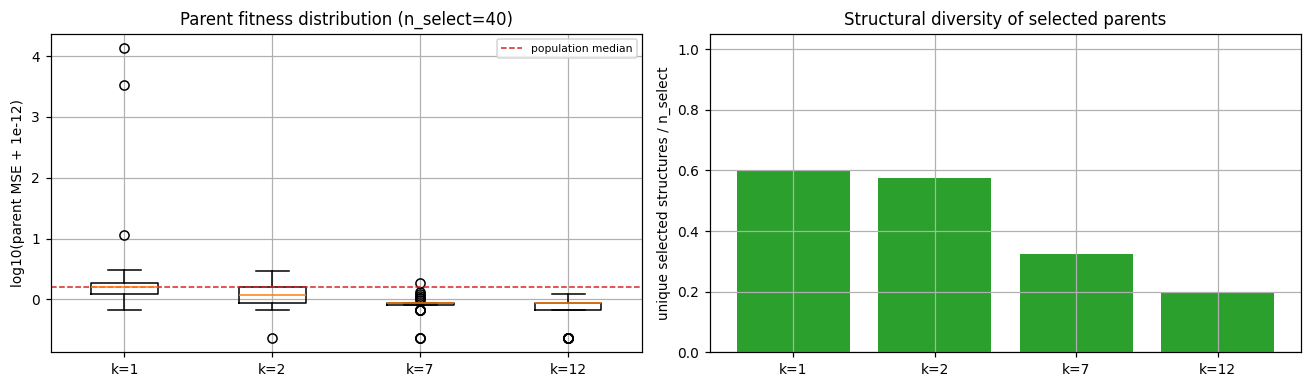

In [13]:
# E04 可视化：父本适应度分布（对数尺度）与结构多样性
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))

log_fits = [np.log10(np.asarray(row["parent_fitnesses"], dtype=float) + 1e-12) for row in e04_rows]
axes[0].boxplot(log_fits)
axes[0].set_xticks(range(1, len(e04_rows) + 1))
axes[0].set_xticklabels([f"k={row['tournament_size']}" for row in e04_rows])
axes[0].axhline(np.log10(np.median(e04_fitnesses) + 1e-12), color="tab:red",
                ls="--", lw=1, label="population median")
axes[0].set_ylabel("log10(parent MSE + 1e-12)")
axes[0].set_title(f"Parent fitness distribution (n_select={E04_N_SELECT})")
axes[0].legend(fontsize=7)

axes[1].bar(range(len(e04_rows)), [row["unique_parent_ratio"] for row in e04_rows],
            color="tab:green")
axes[1].set_xticks(range(len(e04_rows)))
axes[1].set_xticklabels([f"k={row['tournament_size']}" for row in e04_rows])
axes[1].set_ylabel("unique selected structures / n_select")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Structural diversity of selected parents")
fig.tight_layout()

print("提示：本图只回答“这一步选择偏向谁”。它不能回答“多代之后谁进化得更好”。")

### 观察与解释（请填写）

> **观察与解释（请填写）**：k 增大时父本 MSE 的中位数怎样变化？唯一结构比例怎样变化？
> 理论 $P_{\text{best}}$ 与实际观察一致吗？为什么 k=1 的均值与种群均值可能差很多？
> “选择压力更强”能推出“最终进化一定更好”吗？请写下你需要什么实验才能检验后半句。

**本章局限**：只观察了一步选择，没有进化；父本适应度分布受初始种群随机性影响，换一个初始化
种子结论可能变化（Chapter 7 讨论种子分布）。重尾分布下均值不稳定，中位数更稳健，但也不能
代表整个分布。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 5：遗传操作

**核心问题**：交叉、变异、复制分别怎样改变结构？深度限制与回退机制在保护什么？

### 概念与数学定义

本项目实现三种算子（函数集全为二元运算，因此树的每个内部节点有两个子节点）：

| 算子 | 默认概率 | 做法 | 深度控制 |
|---|---|---|---|
| `crossover(p1, p2)` | 0.7 | 两父本各均匀选一个节点，交换其子树，产生两个子代 | 子代深度 $>17$ 时重选交叉点，最多 20 次；仍超限则回退为父本副本 |
| `mutate(ind)` | 0.2 | 均匀选一个节点，用 grow 新子树替换 | 新子树深度 $\le \max\_depth - $ 变异点路径长度 |
| `reproduce(ind)` | 0.1 | 深拷贝 | 无 |

记交叉点路径长度为 $L_1,L_2$，被交换子树深度为 $D_1,D_2$，则两个子代深度分别为
$L_1+D_2$、$L_2+D_1$；只有两者都 $\le \max\_depth$ 时这次交叉才被接受。

**继承与破坏**：交叉可以保留父本的有用子结构（如果交换点选在无关子树），也可以拆散它；
变异可能引入新结构，也可能只是**中性替换**（结构变了、适应度几乎不变）。

**复杂度增长**：交叉/变异都可能让树变大；在只有 MSE 的目标下，稍大的树偶尔能拟合得更好，
于是“膨胀”（bloat）可能被间接奖励——这需要实验检验，不能预设（Chapter 8）。

### 具体小例子

`p1 = (+ x (* x x))`（$x+x^2$）、`p2 = (* (+ x x) x)`（$2x^2$）。若在 p1 的左叶子与
p2 的右子树上交叉，子代可能变成 `(+ (* x x) (* x x))`（$2x^2$）等结构。

### 源码入口

- `gptoy/variation.py` → `crossover`、`mutate`、`reproduce`、`apply_variation`
- 追踪版本：`crossover_traced`、`mutate_traced`、`apply_variation_traced`（返回
  `CrossoverTrace` / `MutationTrace` / `VariationRecord`，RNG 消费顺序与普通版本完全一致）
- 树路径操作：`gptoy/representation.py` → `iter_nodes`、`subtree_at`、`replace_subtree`

### E05：真实执行一次交叉与一次变异

**研究问题**：一次交叉/变异究竟改动了哪棵子树？子代结构与适应度相对父本如何变化？
深度上限触发回退时，算子实际返回什么？

**核心概念**：交叉点/变异点、继承/破坏、中性变化、深度预算与回退。

**可修改配置**（改下面单元顶部变量后重跑）：

- `E05_PARENT_INDICES`：从固定种群中选哪两个父本；
- `E05_DEMO_MAX_DEPTH`：演示用深度上限（**调小以便画图**；默认算法仍用 17）；
- `E05_CROSSOVER_SEED` / `E05_MUTATION_SEED`：算子随机种子。

**运行入口**：接下来两个代码单元（`# E05`）。

**源码位置**：`gptoy/variation.py` 的 traced 接口；`gptoy/viz.py` → `draw_tree`。

> **我的预测（请填写）**：交叉点被标红后，子代是否真的替换了那棵子树？子代适应度会更好、
> 更差还是持平？变异点是叶子还是内部节点？变异后结构一定改变吗？回退时子代与父本是什么关系？

In [14]:
# E05-A 真实交叉：记录交叉点、子代、前后适应度与结构变化
E05_PARENT_INDICES = (0, 1)
E05_DEMO_MAX_DEPTH = 6          # 仅用于让图可读；算法默认 max_tree_depth=17
E05_CROSSOVER_SEED = 21

e05_cfg = replace(e04_cfg, max_tree_depth=E05_DEMO_MAX_DEPTH)
p1 = e04_population[E05_PARENT_INDICES[0]]
p2 = e04_population[E05_PARENT_INDICES[1]]
cross = crossover_traced(p1, p2, e05_cfg, make_rng(E05_CROSSOVER_SEED))

print("父本 1:", p1.sexpr_str())
print("父本 2:", p2.sexpr_str())
print(f"交叉点路径：p1={cross.point1}, p2={cross.point2}；fallback={cross.fallback}")
print()
print("子代 1:", cross.child1.sexpr_str())
print("子代 2:", cross.child2.sexpr_str())
print()
print_table(
    ["个体", "size", "depth", "训练 MSE", "相对父本1", "相对父本2"],
    [
        (name, tree.size(), tree.depth(), f"{fitness(tree, x_train, y_train):.6g}",
         "-", "-")
        for name, tree in (("parent1", p1), ("parent2", p2))
    ]
    + [
        (name, tree.size(), tree.depth(), f"{fitness(tree, x_train, y_train):.6g}",
         "更好" if fitness(tree, x_train, y_train) < fitness(p1, x_train, y_train) else "不更好",
         "更好" if fitness(tree, x_train, y_train) < fitness(p2, x_train, y_train) else "不更好")
        for name, tree in (("child1", cross.child1), ("child2", cross.child2))
    ],
)
print(f"交叉是否改变结构？结构确实变化：{cross.child1 != p1 or cross.child2 != p2}")

父本 1: (* (/ (/ x x) (+ x x)) (+ (- x x) (/ x x)))
父本 2: (- (+ (/ (/ x x) (/ x x)) (+ (/ x x) (- x x))) (* (- (/ x x) (/ x x)) (- (+ x x) (/ x x))))
交叉点路径：p1=(0, 0), p2=(0, 1, 1)；fallback=False

子代 1: (* (/ (- x x) (+ x x)) (+ (- x x) (/ x x)))
子代 2: (- (+ (/ (/ x x) (/ x x)) (+ (/ x x) (/ x x))) (* (- (/ x x) (/ x x)) (- (+ x x) (/ x x))))

个体     size  depth  训练 MSE  相对父本1  相对父本2
-------  ----  -----  --------  ---------  ---------
parent1  15    4      11.3746   -          -        
parent2  31    5      3.38663   -          -        
child1   15    4      1.83433   更好       更好     
child2   31    5      7.16277   更好       不更好   
交叉是否改变结构？结构确实变化：True


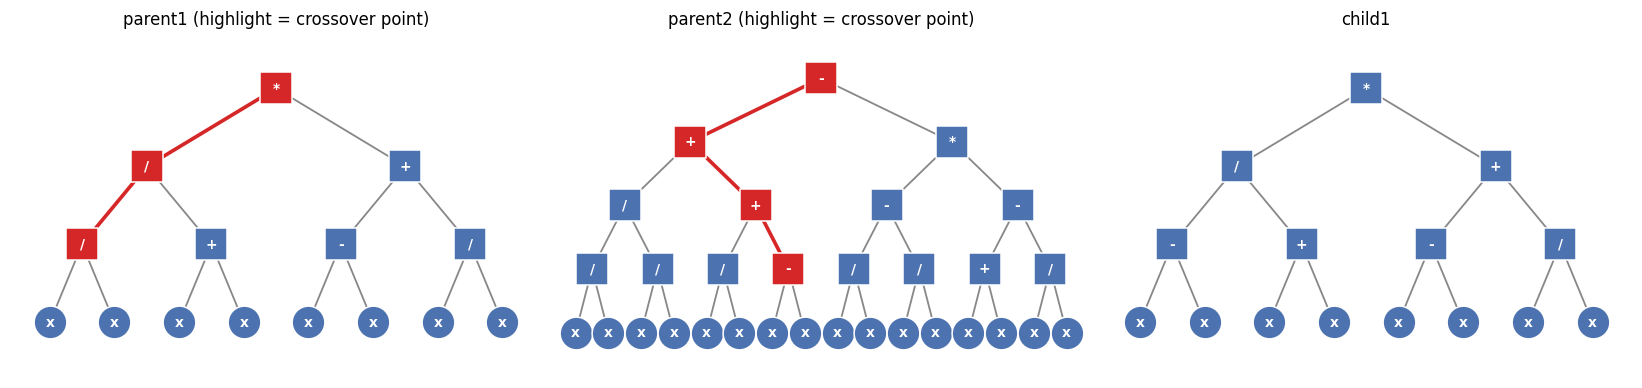

In [15]:
# E05-A 绘图：高亮父本中的交叉点
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
draw_tree(axes[0], p1, title="parent1 (highlight = crossover point)", highlight_paths=[cross.point1])
draw_tree(axes[1], p2, title="parent2 (highlight = crossover point)", highlight_paths=[cross.point2])
draw_tree(axes[2], cross.child1, title="child1")
fig.tight_layout()

变异点路径：(1, 1, 1)（长度 3）；新子树深度 3
变异前: (* (/ (/ x x) (+ x x)) (+ (- x x) (/ x x)))
变异后: (* (/ (/ x x) (+ x x)) (+ (- x x) (/ x (- (- x x) (- x x)))))
个体    size  depth  训练 MSE  结构是否改变
------  ----  -----  --------  ------------
变异前  15    4      11.3746   -           
变异后  21    6      11.3746   True        

回退演示：父本深度均为 10，max_tree_depth=5
  fallback=True，child1==parent1：True，child2==parent2：True


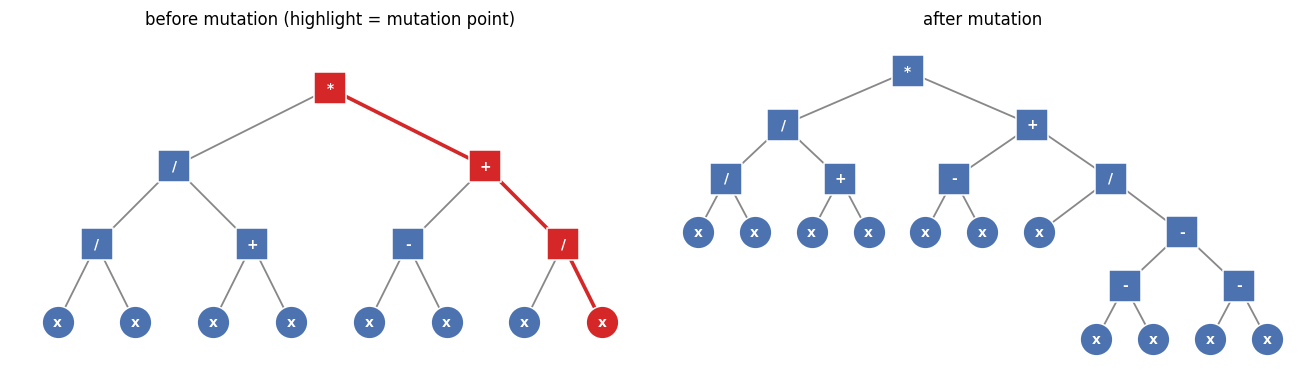

In [16]:
# E05-B 真实变异 + 深度回退演示
E05_MUTATION_SEED = 22
mutation = mutate_traced(p1, e05_cfg, make_rng(E05_MUTATION_SEED))

print(f"变异点路径：{mutation.point}（长度 {len(mutation.point)}）；新子树深度 {mutation.new_subtree_depth}")
print("变异前:", p1.sexpr_str())
print("变异后:", mutation.child.sexpr_str())
print_table(
    ["个体", "size", "depth", "训练 MSE", "结构是否改变"],
    [
        ("变异前", p1.size(), p1.depth(), f"{fitness(p1, x_train, y_train):.6g}", "-"),
        ("变异后", mutation.child.size(), mutation.child.depth(),
         f"{fitness(mutation.child, x_train, y_train):.6g}",
         mutation.child != p1),
    ],
)
print()

# 深度回退：两棵深度 10 的满树在 max_tree_depth=5 下交叉，必然超深 -> 回退为父本副本
deep1 = make_full(10, cfg, make_rng(1))
deep2 = make_full(10, cfg, make_rng(2))
fallback_cfg = replace(cfg, max_tree_depth=5)
fallback_trace = crossover_traced(deep1, deep2, fallback_cfg, make_rng(3))
print(f"回退演示：父本深度均为 {deep1.depth()}，max_tree_depth=5")
print(f"  fallback={fallback_trace.fallback}，child1==parent1：{fallback_trace.child1 == deep1}，"
      f"child2==parent2：{fallback_trace.child2 == deep2}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
draw_tree(axes[0], p1, title="before mutation (highlight = mutation point)",
          highlight_paths=[mutation.point])
draw_tree(axes[1], mutation.child, title="after mutation")
fig.tight_layout()

### 观察与解释（请填写）

> **观察与解释（请填写）**：交叉点是否落在你从表达式上预期的位置？子代是否真的交换了那棵
> 子树？子代适应度比父本更好还是更差？变异点是叶子还是内部节点，结构改变后适应度变了多少？
> 回退时子代与父本是什么关系，为什么必须回退？请把“结构变化”与“适应度变化”分开描述。

**本章局限**：演示用的深度上限被调小（6），因此画出的树比默认算法中的树小；这只影响
可视化，不影响算子语义。单次算子执行结果是随机样本，不能据此推断算子的平均效果。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 6：完整进化过程

**核心问题**：一代完整进化包含哪些步骤？逐代执行与一次性运行是否等价？停止条件怎样影响观察？

### 概念与数学定义

**生成式进化（generational）**：每一代用当前种群产生等规模的新种群，整代同步替换。
本项目的新一代构成为

$$\text{new} = \underbrace{[\,\text{elite}\,]\times e}_{\text{精英保留}} \;\Vert\;
\texttt{apply\_variation}(\text{parents}),$$

其中 $e=\text{elitism\_size}=1$，父本由锦标赛从上一代选出 $N-e$ 个。

**best-of-generation / best-of-run / Hall of Fame**：

- best-of-generation：当前代适应度最小的个体；
- best-of-run：截至当前所有代中最好的个体（按适应度严格变优时更新）；
- Hall of Fame：历代 best-of-run 的副本序列，便于回看“何时发现了更好的解”。

**停止条件**：`stop_on_target=True`（默认）时训练 MSE 首次低于 `mse_target` 就停止；
`stop_on_target=False` 时继续跑满 `max_generations`，用于观察长期行为（Chapter 8）。

**收敛曲线**：由于精英保留，下一代一定包含上一代最优个体，所以 **best MSE 单调不增**
（在同一个适应度定义下）。曲线的台阶对应“发现了更好的个体”。

### 具体小例子

若第 3 代最优个体被复制到第 4 代，而第 4 代没有更好的子代，则第 4 代 best MSE 与第 3 代
相同；一旦某个子代更好，best MSE 下降。若第 0 代就达标，则 `generation_found=0`——
这正是旧版种子搜索要避免的情况（否则看不到进化过程）。

### 源码入口

- 引擎与结果：`gptoy/evolution.py` → `EvolutionEngine.initialize/step/run`、`run_gp`、`RunResult`
- 快照与事件：`gptoy/tracing.py` → `GenerationSnapshot`、`GeneticEvent`、`EvolutionTracer`
- 评估计数：`EvolutionEngine.evaluations`（每评价一代种群计 `population_size` 次）

### E06：逐代执行一次完整的 GP

**研究问题**：如何显式地初始化、逐代推进、查看每代最优与真实遗传事件，并连续运行到停止？
逐代执行与一次性 `run_gp` 的历史是否完全一致？

**核心概念**：generational、elitism、best-of-run、Hall of Fame、停止条件、收敛曲线、
逐代/批量同引擎。

**可修改配置**（改下面单元顶部变量后重跑）：

- `E06_SEED`、`E06_STEPS_BEFORE_PRINT`：种子与先手动推进的代数；
- 也可直接构造 `GPConfig(population_size=..., max_generations=..., ...)` 观察不同预算。

**运行入口**：接下来三个代码单元（`# E06`）。

**源码位置**：`EvolutionEngine.initialize/step/run`；事件由 `apply_variation_traced` 与
精英保留记录，经 `EvolutionTracer` 收集。

> **我的预测（请填写）**：第 0 代最优个体的表达式是什么？前两代 best MSE 会明显下降吗？
> “逐代 step”与“run_gp”的历史会有哪怕一位不同吗？精英保留事件里，子代表达式与父本相同吗？

In [17]:
# E06-A 初始化第 0 代并查看快照
E06_SEED = 3
e06_cfg = GPConfig(seed=E06_SEED)
tracer = EvolutionTracer()
engine = EvolutionEngine(e06_cfg, tracer)

snap0 = engine.initialize()
best0_idx = int(np.argmin(engine.fitnesses))
print(f"第 0 代：population={len(engine.population)}，evaluations={engine.evaluations}")
print(f"best 表达式：{engine.population[best0_idx].sexpr_str()}")
print_table(
    ["快照字段", "值"],
    [
        ("generation", snap0.generation),
        ("best_train_mse", f"{snap0.best_train_mse:.6g}"),
        ("best_test_mse", f"{snap0.best_test_mse:.6g}"),
        ("mean / median / worst", f"{snap0.mean_fitness:.4g} / {snap0.median_fitness:.4g} / {snap0.worst_fitness:.4g}"),
        ("mean_size / max_size", f"{snap0.mean_size:.2f} / {snap0.max_size}"),
        ("mean_depth / max_depth", f"{snap0.mean_depth:.2f} / {snap0.max_depth}"),
        ("unique_structures / ratio", f"{snap0.unique_structures} / {snap0.unique_ratio:.3f}"),
        ("evaluations", snap0.evaluations),
    ],
)

第 0 代：population=100，evaluations=100
best 表达式：(* (+ (/ x x) x) (* (+ x x) (/ x x)))
快照字段                   值                          
-------------------------  ----------------------------
generation                 0                           
best_train_mse             0.0964771                   
best_test_mse              75.1135                     
mean / median / worst      4.244e+05 / 1.834 / 4.24e+07
mean_size / max_size       20.02 / 63                  
mean_depth / max_depth     3.99 / 6                    
unique_structures / ratio  82 / 0.820                  
evaluations                100                         


In [18]:
# E06-B 逐代推进：每代查看快照变化与真实事件
E06_STEPS_BEFORE_PRINT = 2
snapshot_rows = [(snap0.generation, f"{snap0.best_train_mse:.4g}",
                  f"{snap0.mean_fitness:.4g}", f"{snap0.median_fitness:.4g}",
                  f"{snap0.worst_fitness:.4g}", f"{snap0.mean_size:.1f}",
                  snap0.max_size, f"{snap0.unique_ratio:.3f}")]

for _ in range(E06_STEPS_BEFORE_PRINT):
    snap = engine.step()
    snapshot_rows.append((snap.generation, f"{snap.best_train_mse:.4g}",
                          f"{snap.mean_fitness:.4g}", f"{snap.median_fitness:.4g}",
                          f"{snap.worst_fitness:.4g}", f"{snap.mean_size:.1f}",
                          snap.max_size, f"{snap.unique_ratio:.3f}"))
    events = tracer.events_of_generation(snap.generation)
    counts = {}
    for event in events:
        counts[event.event_type] = counts.get(event.event_type, 0) + 1
    print(f"\n第 {snap.generation} 代：完成 {len(events)} 个遗传事件 {counts}")
    for event_type in ("elitism", "crossover", "mutation", "reproduction"):
        examples = [e for e in events if e.event_type == event_type]
        if not examples:
            continue
        example = examples[0]
        point = example.crossover_points if example.crossover_points is not None else example.mutation_point
        print(f"  {event_type:<12} 父本下标={example.parent_indices} "
              f"父本适应度={tuple(f'{v:.4g}' for v in (example.parent_fitnesses or ()))}")
        print(f"  {'':<12} 点={point} fallback={example.fallback} changed={example.changed} "
              f"子代适应度={tuple(f'{v:.4g}' for v in (example.child_fitnesses or ()))}")
        print(f"  {'':<12} 父本表达式={example.parent_expressions[0][:80]}")
        print(f"  {'':<12} 子代表达式={example.child_expressions[0][:80]}")

print()
print_table(
    ["gen", "best train", "mean", "median", "worst", "mean size", "max size", "unique ratio"],
    snapshot_rows,
)


第 1 代：完成 58 个遗传事件 {'elitism': 1, 'crossover': 42, 'mutation': 8, 'reproduction': 7}
  elitism      父本下标=(78,) 父本适应度=('0.09648',)
               点=None fallback=False changed=False 子代适应度=('0.09648',)
               父本表达式=(* (+ (/ x x) x) (* (+ x x) (/ x x)))
               子代表达式=(* (+ (/ x x) x) (* (+ x x) (/ x x)))
  crossover    父本下标=(17, 27) 父本适应度=('0.8603', '0.9789')
               点=((0,), (0, 1, 0, 0)) fallback=False changed=False 子代适应度=('0.8603', '0.9789')
               父本表达式=(+ x x)
               子代表达式=(+ x x)
  mutation     父本下标=(16,) 父本适应度=('0.8603',)
               点=() fallback=False changed=True 子代适应度=('8.064e+18',)
               父本表达式=(+ (+ x x) (- x x))
               子代表达式=(+ (+ (+ (* (* (/ x (/ x (* (+ (+ (- (* x (/ (* x (/ (- x x) (* x x))) (- (- x (
  reproduction 父本下标=(32,) 父本适应度=('0.8603',)
               点=None fallback=False changed=False 子代适应度=('0.8603',)
               父本表达式=(+ x x)
               子代表达式=(+ x x)



第 2 代：完成 58 个遗传事件 {'elitism': 1, 'crossover': 42, 'mutation': 8, 'reproduction': 7}
  elitism      父本下标=(0,) 父本适应度=('0.09648',)
               点=None fallback=False changed=False 子代适应度=('0.09648',)
               父本表达式=(* (+ (/ x x) x) (* (+ x x) (/ x x)))
               子代表达式=(* (+ (/ x x) x) (* (+ x x) (/ x x)))
  crossover    父本下标=(39, 30) 父本适应度=('0.8603', '0.09648')
               点=((1,), (0, 0)) fallback=False changed=True 子代适应度=('0.755', '2.255')
               父本表达式=(+ x x)
               子代表达式=(+ x (/ x x))
  mutation     父本下标=(73,) 父本适应度=('0.755',)
               点=(0, 0, 0) fallback=False changed=True 子代适应度=('1.288e+06',)
               父本表达式=(+ (+ (/ x x) x) (* (- x x) (+ x x)))
               子代表达式=(+ (+ (/ (* (- (+ (- (* x (/ x (+ x (/ x (- (- (- (* (/ x x) (* x x)) (- x (- x 
  reproduction 父本下标=(49,) 父本适应度=('0.755',)
               点=None fallback=False changed=False 子代适应度=('0.755',)
               父本表达式=(+ x (/ x x))
               子代表达式=(+ x (/ x x))

gen  best train

In [19]:
# E06-C 连续运行到停止 + 与一次性 run_gp 对比
while not engine.done:
    engine.step()
stepped = engine.result
fresh = run_gp(e06_cfg)

print(f"逐代运行停止原因：{stepped.stop_reason}；代数={stepped.n_generations}；"
      f"评估次数={stepped.evaluations}")
print(f"一次性运行停止原因：{fresh.stop_reason}；代数={fresh.n_generations}；"
      f"评估次数={fresh.evaluations}")
print()
print_table(
    ["一致性检查", "结果"],
    [
        ("best_mse_history 相同", stepped.best_mse_history == fresh.best_mse_history),
        ("best_of_run 表达式相同", stepped.best_of_run.sexpr_str() == fresh.best_of_run.sexpr_str()),
        ("evaluations 相同", stepped.evaluations == fresh.evaluations),
        ("snapshots 代数相同", [s.generation for s in stepped.snapshots] == [s.generation for s in fresh.snapshots]),
        ("Hall of Fame 长度", f"{len(stepped.hall_of_fame)}（两次运行一致：{len(stepped.hall_of_fame) == len(fresh.hall_of_fame)}）"),
    ],
)
print("\n最终表达式：", stepped.best_of_run.sexpr_str())
print(f"训练 MSE={stepped.train_mse:.3e}，测试 MSE={stepped.test_mse:.3e}")
print("\nHall of Fame（历代严格变优时追加的个体副本）：")
for rank, tree in enumerate(stepped.hall_of_fame):
    print(f"  #{rank}: size={tree.size():3d} depth={tree.depth():2d} "
          f"expr={tree.sexpr_str()[:70]}")

逐代运行停止原因：converged；代数=5；评估次数=600
一次性运行停止原因：converged；代数=5；评估次数=600

一致性检查              结果                   
----------------------  -----------------------
best_mse_history 相同   True                   
best_of_run 表达式相同  True                   
evaluations 相同        True                   
snapshots 代数相同      True                   
Hall of Fame 长度       4（两次运行一致：True）

最终表达式： (* (+ (* x x) x) (* (* x (+ (+ (/ (/ x x) x) x) (* (- x x) (+ x x)))) (/ x x)))
训练 MSE=5.367e-32，测试 MSE=3.234e-30

Hall of Fame（历代严格变优时追加的个体副本）：
  #0: size= 13 depth= 4 expr=(* (+ (/ x x) x) (* (+ x x) (/ x x)))
  #1: size= 11 depth= 4 expr=(+ (+ (* x x) x) (+ (* x x) x))
  #2: size= 15 depth= 5 expr=(* (+ (/ x x) x) (* (+ (* x x) x) (/ x x)))
  #3: size= 27 depth= 8 expr=(* (+ (* x x) x) (* (* x (+ (+ (/ (/ x x) x) x) (* (- x x) (+ x x)))) 


注意：纵轴使用对数；inf 值被画成断点（数值异常个体被策略固定为 inf）。


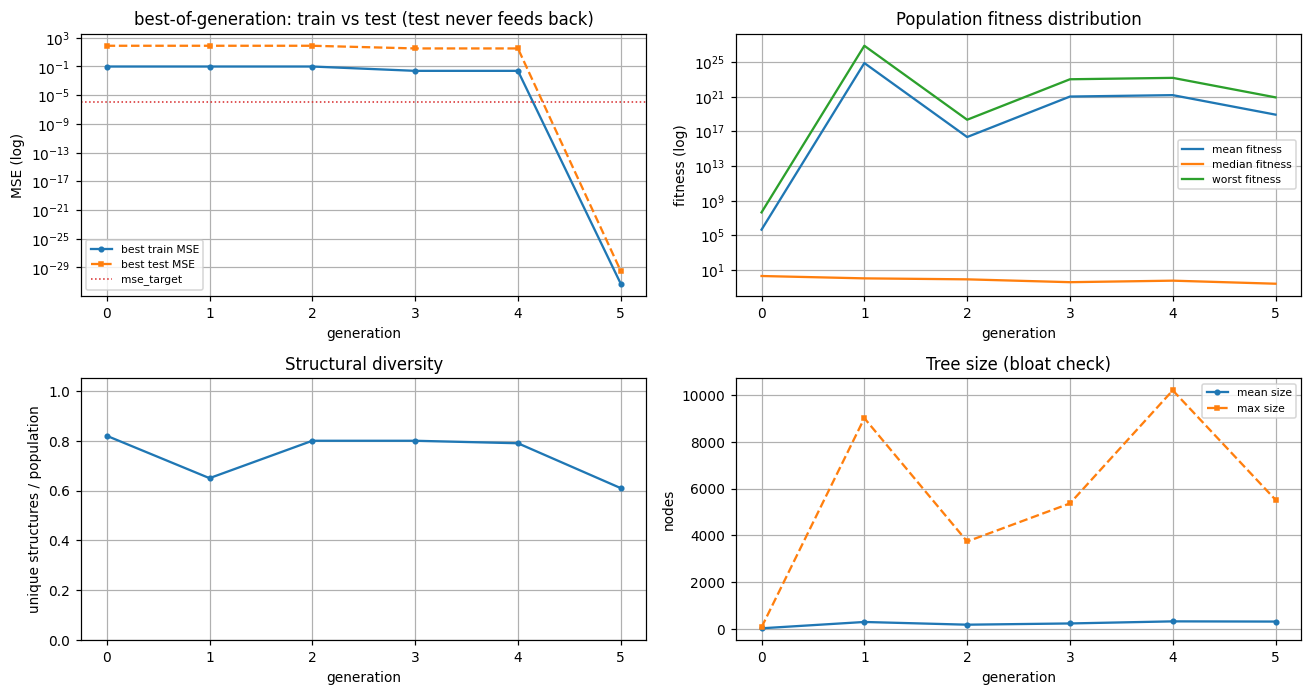

In [20]:
# E06-D 收敛曲线、适应度分布与多样性/复杂度演化
snaps = stepped.snapshots
gens = [s.generation for s in snaps]
finite_or_nan = lambda values: [v if np.isfinite(v) else np.nan for v in values]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.4))

axes[0, 0].semilogy(gens, finite_or_nan([s.best_train_mse for s in snaps]), "-o", ms=3, label="best train MSE")
axes[0, 0].semilogy(gens, finite_or_nan([s.best_test_mse for s in snaps]), "--s", ms=3, label="best test MSE")
axes[0, 0].axhline(e06_cfg.mse_target, color="tab:red", ls=":", lw=1, label="mse_target")
axes[0, 0].set_xlabel("generation")
axes[0, 0].set_ylabel("MSE (log)")
axes[0, 0].set_title("best-of-generation: train vs test (test never feeds back)")
axes[0, 0].legend(fontsize=7)

axes[0, 1].semilogy(gens, finite_or_nan([s.mean_fitness for s in snaps]), label="mean fitness")
axes[0, 1].semilogy(gens, finite_or_nan([s.median_fitness for s in snaps]), label="median fitness")
axes[0, 1].semilogy(gens, finite_or_nan([s.worst_fitness for s in snaps]), label="worst fitness")
axes[0, 1].set_xlabel("generation")
axes[0, 1].set_ylabel("fitness (log)")
axes[0, 1].set_title("Population fitness distribution")
axes[0, 1].legend(fontsize=7)

axes[1, 0].plot(gens, [s.unique_ratio for s in snaps], "-o", ms=3)
axes[1, 0].set_xlabel("generation")
axes[1, 0].set_ylabel("unique structures / population")
axes[1, 0].set_title("Structural diversity")
axes[1, 0].set_ylim(0, 1.05)

axes[1, 1].plot(gens, [s.mean_size for s in snaps], "-o", ms=3, label="mean size")
axes[1, 1].plot(gens, [s.max_size for s in snaps], "--s", ms=3, label="max size")
axes[1, 1].set_xlabel("generation")
axes[1, 1].set_ylabel("nodes")
axes[1, 1].set_title("Tree size (bloat check)")
axes[1, 1].legend(fontsize=7)

fig.tight_layout()
print("注意：纵轴使用对数；inf 值被画成断点（数值异常个体被策略固定为 inf）。")

### 观察与解释（请填写）

> **观察与解释（请填写）**：第 0 代到停止，best MSE 是否单调不增？mean/median 是否也单调？
> 结构多样性如何变化？平均树规模有没有上升？逐代与批量的五项一致性检查是否全部通过？
> 从真实事件看，第 1 代精英保留的子代表达式与父本是否完全相同？

**本章局限**：只运行了一个种子；收敛曲线平滑不代表算法稳健。`mean_fitness` 可能被
极少数超大树拉到极大值甚至 inf，因此对数坐标下会出现断点——这本身是“重尾/膨胀”的线索，
但需要 Chapter 8 的对照实验才能判断机制。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

# 第二篇：GP 的典型失败

*Chapter 7–10：随机性与预算、早熟与膨胀、噪声与泛化、空间与数值限制*

> 本部分包含：Chapter 7 随机性与搜索预算、Chapter 8 早熟收敛与表达式膨胀、Chapter 9 小样本、噪声与泛化、Chapter 10 搜索空间与数值语义的限制

## Chapter 7：随机性与搜索预算

> 第二篇导言：第一篇把 GP 的每个阶段单独拆开看了一遍；从本章开始处理“为什么有时失败”。
> 每一章都要求先写预测，再用**预先指定种子**的对照实验检验，而不是用一个成功/失败案例
> 讲故事。

**核心问题**：GP 的随机性来自哪里？预算怎样限制搜索？不同随机种子的结果分布说明了什么？

### 概念与数学定义

**随机性来源**（本项目全部来自同一个 `random.Random(config.seed)`）：

1. 初始化：深度桶、full/grow 选择、节点与运算符抽样；
2. 选择：每轮锦标赛抽到的 $k$ 个下标；
3. 交叉：两个交叉点；
4. 变异：变异点与 grow 新子树；
5. 复制/精英：不消耗随机数（但会改变种群构成）。

**预算**：用**训练适应度评估次数**衡量：

$$\text{evaluations}=N_{\text{pop}}\times(\text{评价过的代数}).$$

它比墙钟时间稳定，也不受机器性能影响。测试集评价不计入预算，也不反馈给搜索。

**首达代**：$\min\{g:\ \mathrm{MSE}_{\text{train}}(g)<\text{mse\_target}\}$；若直到预算用完
都没达到则为 `None`。**成功率**必须说明是训练达标率还是测试达标率。

**重复性**：同一 seed 与配置逐位可复现；不同 seed 是同一随机过程的不同样本。只报告一个
成功种子会系统性高估算法能力——这正是旧版种子搜索的做法，必须明确它的教学性质与偏差。

### 具体小例子

若 6 个种子里只有 2 个训练达标，则训练达标率是 $2/6$；它们的首达代可能分别是 3 和 7。
如果其中一个种子的测试 MSE 很大，测试达标率会更低。**这两个比例不能混为一谈。**

### 源码入口

- 引擎的预算与停止：`gptoy/evolution.py` → `EvolutionEngine.evaluations`、`stop_reason`
- 批量与汇总：`gptoy/experiments.py` → `run_seed_batch`、`run_budget_experiment`、`summarize_runs`
- 随机源：`gptoy/utils.py` → `make_rng`

### E07：多种子 × 多预算

**研究问题**：在预先指定的种子集合上，不同搜索预算下的最终训练/测试 MSE、训练/测试达标率、
首达代与实际评估次数如何分布？种子之间的差异有多大？

**核心概念**：种子分布、预算、首达代、训练/测试达标率、结构恢复代理。

**可修改配置**（改下面单元顶部变量后重跑）：

- `E07_SEEDS`：**预先指定**的种子（不要看结果再换）；
- `E07_BUDGETS`：最大代数预算；
- `E07_POP_SIZE`、`E07_MAX_DEPTH`：种群与深度上限（调小是为了在几十秒内跑完）。

**运行入口**：接下来两个代码单元（`# E07`）。

**源码位置**：`run_budget_experiment` → `run_seed_batch` → 同一 `EvolutionEngine`；
汇总用 `summarize_runs`（结构恢复率默认 `None`，因为这里没有可靠的结构判别器）。

> **我的预测（请填写）**：预算从 5 代增加到 15 代，训练达标率会提高吗？测试达标率呢？
> 种子之间的最终 MSE 会差几个数量级？首达代的分布是集中还是分散？实际评估次数等于
> 种群规模 × (预算+1) 吗？

In [21]:
# E07 预先指定种子与预算，保留全部结果
E07_SEEDS = (0, 1, 2, 3, 4, 5)
E07_BUDGETS = (5, 15)
E07_POP_SIZE = 40
E07_MAX_DEPTH = 9

e07_base = replace(cfg, population_size=E07_POP_SIZE, max_tree_depth=E07_MAX_DEPTH,
                   stop_on_target=False)  # 关闭提前停止，预算才会被真正消耗
e07_results = run_budget_experiment(e07_base, E07_SEEDS, E07_BUDGETS)

rows = []
for budget, results in e07_results.items():
    for r in results:
        rows.append((budget, r.seed, f"{r.train_mse:.3e}", f"{r.test_mse:.3e}",
                     r.generation_found, r.n_generations, r.evaluations))
print_table(["budget", "seed", "final train MSE", "final test MSE", "first hit gen",
             "generations", "evaluations"], rows)
print("\n说明：测试 MSE 只用于最终报告，没有参与任何选择或种子筛选。")

budget  seed  final train MSE  final test MSE  first hit gen  generations  evaluations
------  ----  ---------------  --------------  -------------  -----------  -----------
5       0     2.223e-32        2.603e-30       3              5            240        
5       1     7.690e-02        7.194e+01       None           5            240        
5       2     2.411e-02        3.184e+01       None           5            240        
5       3     6.471e-33        2.840e-30       4              5            240        
5       4     3.412e-02        6.508e+01       None           5            240        
5       5     2.411e-02        3.184e+01       None           5            240        
15      0     2.223e-32        2.603e-30       3              15           640        
15      1     3.371e-02        1.587e+01       None           15           640        
15      2     5.319e-32        1.341e-30       7              15           640        
15      3     6.471e-33        2.840e-30   

In [22]:
# E07 汇总：训练/测试达标率、首达代、评估次数（全部种子，不筛选）
print_table(
    ["budget", "train 达标率", "test 达标率", "首达代 values", "首达代中位数",
     "平均评估次数", "失败种子（训练）"],
    [
        (budget,
         f"{summary['train_success_rate']:.2f}",
         f"{summary['test_success_rate']:.2f}",
         summary['first_hit_generation']['values'],
         summary['first_hit_generation']['median'],
         f"{summary['evaluations']['mean']:.0f}",
         summary['failed_train_seeds'])
        for budget, results in e07_results.items()
        for summary in [summarize_runs(results)]
    ],
)
print()
for budget, results in e07_results.items():
    summary = summarize_runs(results)
    print(f"budget={budget}: 结构恢复率 = {summary['structural_recovery_rate']} "
          f"（{summary['structural_recovery_note']}）")

budget  train 达标率  test 达标率  首达代 values  首达代中位数  平均评估次数  失败种子（训练）
------  ------------  -----------  -------------  ------------  ------------  ----------------
5       0.33          0.33         [3, 4]         3.5           240           [1, 2, 4, 5]    
15      0.67          0.67         [3, 7, 4, 12]  5.5           640           [1, 5]          

budget=5: 结构恢复率 = None （unavailable：没有可靠的全域结构等价判定器；仅当显式提供 strict_expression（精确树匹配）时启用，且该比例是下界。）
budget=15: 结构恢复率 = None （unavailable：没有可靠的全域结构等价判定器；仅当显式提供 strict_expression（精确树匹配）时启用，且该比例是下界。）


每个点是一个预先指定的种子；如果只展示最好的种子，就会隐藏这里看到的大部分失败。


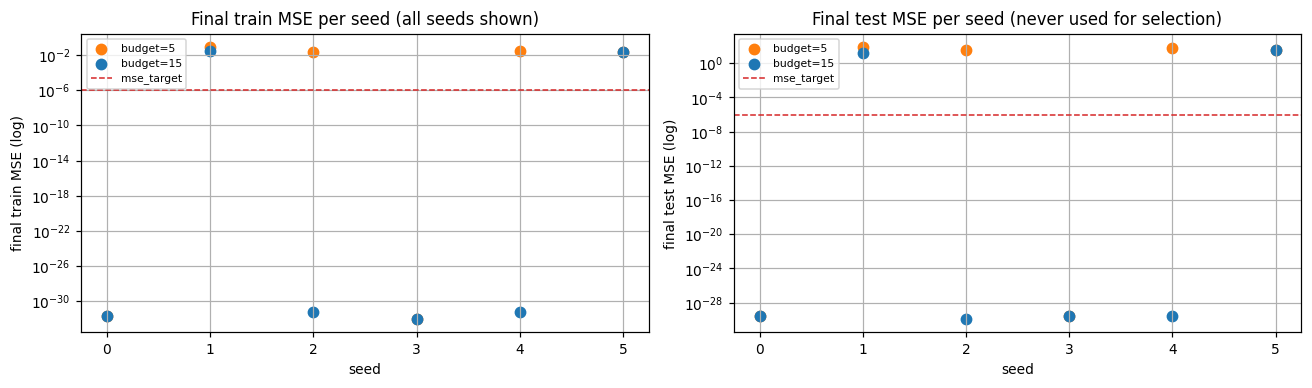

In [23]:
# E07 可视化：种子差异（每个点是一个真实种子）
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
colors = {5: "tab:orange", 15: "tab:blue"}

for budget, results in e07_results.items():
    seeds = [r.seed for r in results]
    train = [max(r.train_mse, 1e-32) for r in results]
    test = [max(r.test_mse, 1e-32) for r in results]
    axes[0].scatter(seeds, train, label=f"budget={budget}", color=colors[budget], s=45)
    axes[1].scatter(seeds, test, label=f"budget={budget}", color=colors[budget], s=45)

axes[0].axhline(e07_base.mse_target, color="tab:red", ls="--", lw=1, label="mse_target")
axes[0].set_yscale("log")
axes[0].set_xticks(E07_SEEDS)
axes[0].set_xlabel("seed")
axes[0].set_ylabel("final train MSE (log)")
axes[0].set_title("Final train MSE per seed (all seeds shown)")
axes[0].legend(fontsize=7)

axes[1].axhline(e07_base.mse_target, color="tab:red", ls="--", lw=1, label="mse_target")
axes[1].set_yscale("log")
axes[1].set_xticks(E07_SEEDS)
axes[1].set_xlabel("seed")
axes[1].set_ylabel("final test MSE (log)")
axes[1].set_title("Final test MSE per seed (never used for selection)")
axes[1].legend(fontsize=7)
fig.tight_layout()

print("每个点是一个预先指定的种子；如果只展示最好的种子，就会隐藏这里看到的大部分失败。")

### 观察与解释（请填写）

> **观察与解释（请填写）**：训练达标率与测试达标率分别是多少？两者差距说明什么？
> 首达代分布集中在哪个范围？预算翻倍后，失败种子变少了吗？实际评估次数与
> `种群规模 × (预算+1)` 是否一致？种子之间的最终 MSE 差几个数量级？
> 如果只能用训练集信息做模型选择，你会怎么选？测试集为什么不能参与？

**本章诚实性说明**：

- 种子集合是**事先指定**的，没有根据测试表现增删；
- 这里的预算（5/15 代、种群 40）远小于默认配置，失败率被刻意放大，便于观察分布；
- “结构恢复率”没有计算，因为本实验没有可靠的全域结构判别器；把它写成 0 或 100% 都是误导；
- 默认基线使用的 `seed=3` 来自旧版 `scripts/find_seed.py` 的教学种子搜索。该脚本先用
  训练+测试同时达标的规则筛选种子，再按首达代排序，因此它展示的是“被选中的成功样本”，
  **不能**用来估计无偏成功率；真正的成功率请看本实验的多种子统计。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 8：早熟收敛与表达式膨胀

**核心问题**：选择压力变大会不会让种群过早失去多样性？表达式复杂度会不会无界增长？怎样设计对照实验来检验？

### 概念与数学定义

**早熟收敛（premature convergence）**：种群在尚未耗尽预算、也未必达到全局最优时，
结构多样性快速下降、best 适应度长期停滞。注意它描述的是**过程**，不是“结果不够好”：
一个已经收敛到正确公式的运行也会失去多样性，那是成功收敛。

**多样性指标**（本项目可观察）：

- `unique_ratio = 唯一结构数 / 种群规模`（基于结构签名，见 `metrics.structural_signature`）；
- `fitness_std`：当代适应度的总体标准差；
- `mean_depth` / `max_depth`、`mean_size` / `max_size` 的逐代变化。

**膨胀（bloat）**：平均/最大树规模持续增长，而 best 适应度没有相应改善。常见机制假设是
“稍大的树偶尔能拟合得更好，选择因此间接奖励规模增长”，但本实验不预设它一定发生。

**简约压力（parsimony pressure）**：把搜索目标改成

$$\text{objective}(T)=\mathrm{MSE}(T)+\lambda\cdot\mathrm{size}(T).$$

$\lambda=0$ 时与原目标完全一致；$\lambda>0$ 时选择同时偏好小树。注意这是**实验变体**，
不是原 Koza-1 算法；快照中的 `best_train_mse` 仍是原始 MSE，因此可以观察“误差-复杂度”权衡。

**复杂度限制**：直接降低 `max_tree_depth` 会改变可达结构集合，可能抑制膨胀，也可能
同时砍掉有用的深结构——这是需要实验区分的替代解释。

### 具体小例子

若某配置的 `unique_ratio` 从 0.95 在 5 代内降到 0.2，同时 best MSE 不再下降，则它表现出
“多样性丧失 + 停滞”的**现象**；但停滞也可能来自“搜索空间里没有更好的可达结构”“预算不足”
或“评价噪声”，需要额外对照才能区分机制。

### 源码入口

- 关闭提前停止：`GPConfig(stop_on_target=False)`；`run_gp(..., max_generations=...)`
- 选择压力：`gptoy/selection.py` → `tournament_select`
- 每代统计：`gptoy/metrics.py` → `population_stats`
- 简约目标：`gptoy/experiments.py` → `make_parsimony_fitness`
- 自定义搜索目标：`EvolutionEngine(config, fitness_fn=...)` / `run_gp(..., fitness_fn=...)`

### E08：两组对照实验

**研究问题**：

- A：只改变锦标赛规模 $k\in\{1,7,12\}$，选择压力与搜索过程（best MSE、多样性、规模）如何变化？
- B：改变复杂度限制（`max_tree_depth`）或加入简约惩罚 $\lambda$，复杂度的发展如何变化？

**核心概念**：选择压力、多样性、膨胀、简约压力、复杂度限制、关闭提前停止。

**可修改配置**（改下面单元顶部变量后重跑）：

- `E08A_KS`、`E08A_SEEDS`、`E08A_POP_SIZE`、`E08A_GENERATIONS`；
- `E08B_LAMBDAS`、`E08B_DEPTHS`、`E08B_SEED`。

**运行入口**：接下来三个代码单元（`# E08-A`、`# E08-B`）。

**源码位置**：`run_gp` 的 `stop_on_target=False` 用于跑满预算；
`make_parsimony_fitness(λ)` 提供简约目标。

> **我的预测（请填写）**：k 增大时，`unique_ratio` 会更快下降吗？平均树规模会更大还是更小？
> 加入 $\lambda$ 后，最终原始 MSE 会变差吗？规模会变小吗？降低 `max_tree_depth` 与
> 加入简约惩罚，哪一个更能抑制规模？先写下判断，再用下面的数据检验。

In [24]:
# E08-A 只改变 tournament size：关闭提前停止，跑满预算
E08A_KS = (1, 7, 12)
E08A_SEEDS = (0, 1)
E08A_POP_SIZE = 40
E08A_GENERATIONS = 12
E08A_DEPTH = 9

e08a_base = replace(cfg, population_size=E08A_POP_SIZE,
                    max_generations=E08A_GENERATIONS,
                    max_tree_depth=E08A_DEPTH, stop_on_target=False)
e08a = {
    k: [run_gp(replace(e08a_base, tournament_size=k, seed=seed)) for seed in E08A_SEEDS]
    for k in E08A_KS
}

print_table(
    ["k", "seed", "final train MSE", "test MSE", "unique ratio (last)",
     "mean size (last)", "max size (last)", "evaluations"],
    [
        (k, r.seed, f"{r.train_mse:.4g}", f"{r.test_mse:.4g}",
         f"{r.snapshots[-1].unique_ratio:.3f}", f"{r.snapshots[-1].mean_size:.1f}",
         r.snapshots[-1].max_size, r.evaluations)
        for k, runs in e08a.items() for r in runs
    ],
)

k   seed  final train MSE  test MSE   unique ratio (last)  mean size (last)  max size (last)  evaluations
--  ----  ---------------  ---------  -------------------  ----------------  ---------------  -----------
1   0     5.273e-32        1.972e-30  0.825                58.0              129              520        
1   1     0.02411          31.84      0.925                76.8              229              520        
7   0     2.223e-32        2.603e-30  0.625                20.4              75               520        
7   1     0.0422           17.1       0.775                33.9              67               520        
12  0     5.273e-32        1.972e-30  0.675                21.9              167              520        
12  1     4.145e-32        3.234e-30  0.675                44.6              79               520        


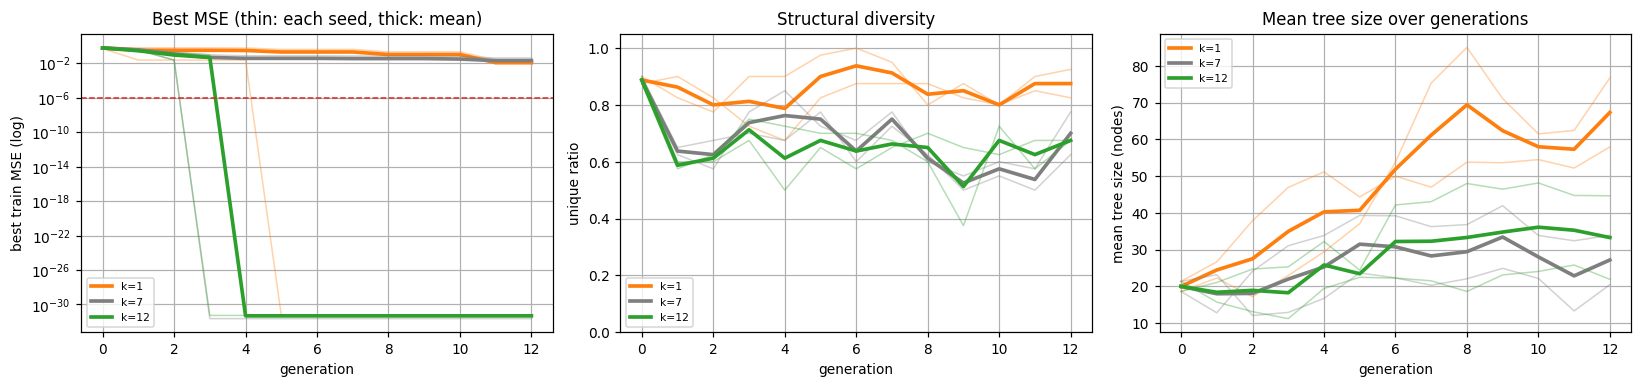

In [25]:
# E08-A 逐代曲线：每个 k 的两种子细线 + 均值粗线
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for k, runs in e08a.items():
    for r in runs:
        axes[0].semilogy([max(v, 1e-32) for v in r.best_mse_history], color=f"C{k % 10}", alpha=0.35, lw=1)
        axes[1].plot([s.unique_ratio for s in r.snapshots], color=f"C{k % 10}", alpha=0.35, lw=1)
        axes[2].plot([s.mean_size for s in r.snapshots], color=f"C{k % 10}", alpha=0.35, lw=1)
    best_curve = np.mean([[max(v, 1e-32) for v in r.best_mse_history] for r in runs], axis=0)
    unique_curve = np.mean([[s.unique_ratio for s in r.snapshots] for r in runs], axis=0)
    size_curve = np.mean([[s.mean_size for s in r.snapshots] for r in runs], axis=0)
    axes[0].semilogy(best_curve, color=f"C{k % 10}", lw=2.4, label=f"k={k}")
    axes[1].plot(unique_curve, color=f"C{k % 10}", lw=2.4, label=f"k={k}")
    axes[2].plot(size_curve, color=f"C{k % 10}", lw=2.4, label=f"k={k}")

axes[0].axhline(e08a_base.mse_target, color="tab:red", ls="--", lw=1)
axes[0].set_xlabel("generation")
axes[0].set_ylabel("best train MSE (log)")
axes[0].set_title("Best MSE (thin: each seed, thick: mean)")
axes[0].legend(fontsize=7)
axes[1].set_xlabel("generation")
axes[1].set_ylabel("unique ratio")
axes[1].set_title("Structural diversity")
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=7)
axes[2].set_xlabel("generation")
axes[2].set_ylabel("mean tree size (nodes)")
axes[2].set_title("Mean tree size over generations")
axes[2].legend(fontsize=7)
fig.tight_layout()

In [26]:
# E08-A 每代明细：best/mean/median/worst 适应度、结构多样性、平均/最大规模
# （选一个代表性配置 k=7、seed=0；其他配置可用同样方式查看）
detail = e08a[7][0]
print_table(
    ["gen", "best train", "mean", "median", "worst", "unique ratio", "mean size", "max size"],
    [
        (s.generation, f"{s.best_train_mse:.4g}", f"{s.mean_fitness:.4g}",
         f"{s.median_fitness:.4g}", f"{s.worst_fitness:.4g}",
         f"{s.unique_ratio:.3f}", f"{s.mean_size:.1f}", s.max_size)
        for s in detail.snapshots
    ],
)
print("\n（这张表就是“每代记录 best MSE、适应度分布、多样性、平均/最大规模”的入口；")
print("  `GenerationSnapshot` 的字段可直接用于你自己的表格或图。）")

gen  best train  mean       median   worst      unique ratio  mean size  max size
---  ----------  ---------  -------  ---------  ------------  ---------  --------
0    0.5309      1.064e+07  1.834    4.255e+08  0.900         21.4       63      
1    0.3535      3089       0.9789   1.235e+05  0.650         23.1       215     
2    0.02411     334.6      0.8603   1.322e+04  0.675         12.1       99      
3    2.223e-32   0.9594     0.7415   5.562      0.700         12.9       97      
4    2.223e-32   15.2       0.3993   514.5      0.675         16.7       97      
5    2.223e-32   1.387      0.6437   14.17      0.775         23.6       173     
6    2.223e-32   3.729      0.09875  90.67      0.600         22.3       139     
7    2.223e-32   2.461e+27  0.5309   9.843e+28  0.725         20.3       111     
8    2.223e-32   0.5578     0.08037  3.357      0.625         22.1       129     
9    2.223e-32   1.068e+07  0.2961   4.27e+08   0.500         24.9       145     
10   2.223e-32  

In [27]:
# E08-B 复杂度限制 vs 简约惩罚
E08B_SEED = 3
E08B_POP_SIZE = 40
E08B_GENERATIONS = 15
E08B_DEPTHS = {"depth<=5": 5, "depth<=9": 9}
E08B_LAMBDAS = {"MSE+0.001*size": 0.001, "MSE+0.01*size": 0.01}

e08b_base = replace(cfg, population_size=E08B_POP_SIZE, max_generations=E08B_GENERATIONS,
                    max_tree_depth=9, stop_on_target=False, seed=E08B_SEED)
e08b = {}
for name, depth in E08B_DEPTHS.items():
    e08b[name] = run_gp(replace(e08b_base, max_tree_depth=depth))
for name, lam in E08B_LAMBDAS.items():
    fitness_fn = make_parsimony_fitness(lam) if lam > 0 else None
    e08b[name] = run_gp(e08b_base, fitness_fn=fitness_fn)

print_table(
    ["variant", "raw train MSE", "test MSE", "final size", "final depth",
     "mean size (last)", "max size (last)", "unique ratio (last)"],
    [
        (name, f"{r.train_mse:.4g}", f"{r.test_mse:.4g}", r.best_of_run.size(),
         r.best_of_run.depth(), f"{r.snapshots[-1].mean_size:.1f}",
         r.snapshots[-1].max_size, f"{r.snapshots[-1].unique_ratio:.3f}")
        for name, r in e08b.items()
    ],
)
print()
print("区分能力检查（本实验内部极差）：")
print(f"  unique_ratio 极差 = {max(r.snapshots[-1].unique_ratio for r in e08b.values()) - min(r.snapshots[-1].unique_ratio for r in e08b.values()):.3f}")
print(f"  mean_size 极差    = {max(r.snapshots[-1].mean_size for r in e08b.values()) - min(r.snapshots[-1].mean_size for r in e08b.values()):.1f}")
print(f"  max_size 极差     = {max(r.snapshots[-1].max_size for r in e08b.values()) - min(r.snapshots[-1].max_size for r in e08b.values())}")
print(f"  raw train MSE 极差= {max(r.train_mse for r in e08b.values()) - min(r.train_mse for r in e08b.values()):.4g}")

variant         raw train MSE  test MSE   final size  final depth  mean size (last)  max size (last)  unique ratio (last)
--------------  -------------  ---------  ----------  -----------  ----------------  ---------------  -------------------
depth<=5        5.32e-32       2.919e-30  15          5            14.6              21               0.450              
depth<=9        6.471e-33      2.84e-30   31          7            32.3              67               0.725              
MSE+0.001*size  0.02411        31.84      19          7            24.2              165              0.525              
MSE+0.01*size   0.02411        31.84      15          6            21.2              151              0.600              

区分能力检查（本实验内部极差）：
  unique_ratio 极差 = 0.275
  mean_size 极差    = 17.7
  max_size 极差     = 144
  raw train MSE 极差= 0.02411


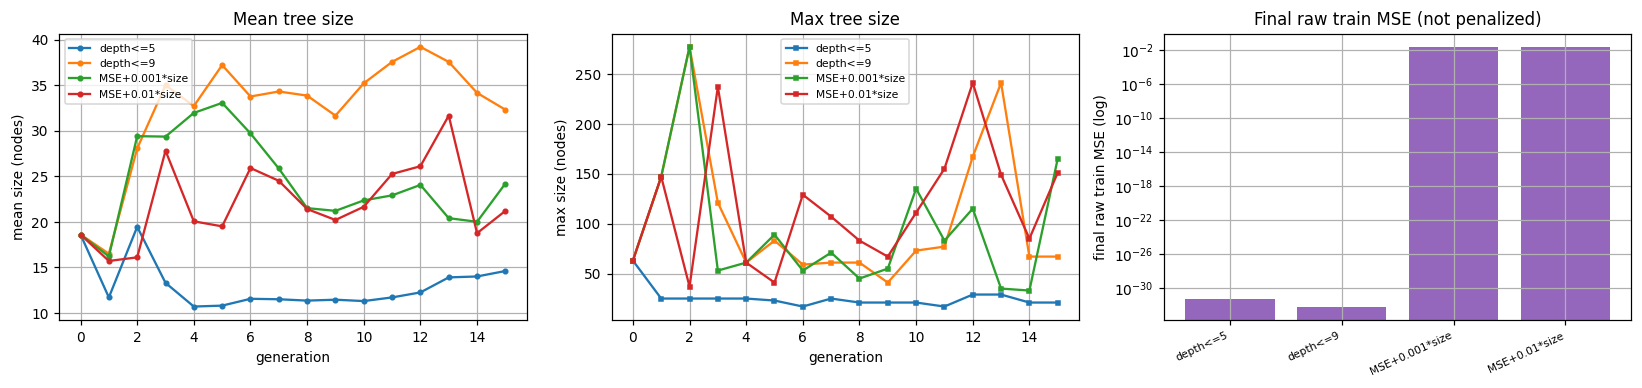

In [28]:
# E08-B 可视化：规模发展与最终误差
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for name, r in e08b.items():
    gens = [s.generation for s in r.snapshots]
    axes[0].plot(gens, [s.mean_size for s in r.snapshots], "-o", ms=3, label=name)
    axes[1].plot(gens, [s.max_size for s in r.snapshots], "-s", ms=3, label=name)
axes[0].set_xlabel("generation")
axes[0].set_ylabel("mean size (nodes)")
axes[0].set_title("Mean tree size")
axes[0].legend(fontsize=7)
axes[1].set_xlabel("generation")
axes[1].set_ylabel("max size (nodes)")
axes[1].set_title("Max tree size")
axes[1].legend(fontsize=7)

positions = np.arange(len(e08b))
axes[2].bar(positions, [max(r.train_mse, 1e-33) for r in e08b.values()], color="tab:purple")
axes[2].set_yscale("log")
axes[2].set_xticks(positions)
axes[2].set_xticklabels(list(e08b), rotation=25, ha="right", fontsize=7)
axes[2].set_ylabel("final raw train MSE (log)")
axes[2].set_title("Final raw train MSE (not penalized)")
fig.tight_layout()

### 观察与解释（请填写）

> **观察与解释（请填写）**：A 组中 k 增大时，`unique_ratio` 的下降速度、平均规模和最终
> best MSE 有什么差别？这些差别在两个种子上一致吗？B 组中哪种手段让规模更小？代价是
> 原始 MSE 变差吗？是否存在“规模变大但误差没有改善”的膨胀现象？
> 如果**没有**观察到预期现象，请如实写下，并引用“区分能力检查”的数字说明实验是否仍有
> 分辨力（例如极差是否接近 0）。

**本章诚实性要求**：本 Notebook **不预设** k 越大越早熟、也不预设一定发生膨胀。
上面的数字来自本次运行；两个种子只是很小的样本，不能据此做普遍性结论。请把
“本次观察到……”“我推测的机制是……”“还需要什么对照才能区分……”分开写。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 9：小样本、噪声与泛化

**核心问题**：训练样本变少或噪声变大时，GP 的泛化会怎样变化？训练/验证/测试应该怎样划分？

### 概念与数学定义

**生成机制**：本实验的数据来自已知目标函数 $f$，训练标签加观测噪声：

$$y_i = f(x_i)+\varepsilon_i,\qquad \varepsilon_i \overset{iid}{\sim} N(0,\sigma^2),$$

$$\sigma = \text{noise\_ratio}\times \mathrm{std}\big(f(x_{\text{train}})\big),$$

其中 `std` 使用**总体标准差（ddof=0）**。噪声随机源由 `data_seed` 单独控制，与 GP 的
`seed` 分离，因此可以固定数据、只改变搜索随机性，反之亦然。

**数据划分**：三个 x 区间互不重叠（默认训练 $[-1,0.9]$、验证 $[1.0,1.4]$、测试 $[1.5,2.0]$），
验证/测试标签保持干净（不加噪声）。测试集只在最后评价。

**注意这是外推（extrapolation）**：测试区间 $[1.5,2.0]$ 完全位于训练区间 $[-1,0.9]$ 之外，
验证区间 $[1.0,1.4]$ 也在训练区间之外。因此本实验的“干净测试 MSE”主要度量**外推误差**，
而不是同分布 i.i.d. 泛化误差；若要估计后者，需要在训练分布内部做独立划分。

**过拟合**：训练误差低但独立测试误差高。GP 中的常见形式是选择出利用训练噪声的复杂结构；
但在小预算下也可能根本拟合不了，表现为训练/测试都差——两种失败要分开看。

**模型选择偏差**：如果用测试集挑种子、挑超参数或挑模型，那么报告出来的测试误差会系统性
偏乐观。正确做法是：用训练/验证做选择，测试只做一次最终评价。

### 具体小例子

若训练集只有 10 个点、噪声 $\sigma\approx0.1$，则即使找到真实函数，训练 MSE 也会在
$\sigma^2\approx0.01$ 附近；此时“训练 MSE 达标 1e-6”本身就不可能。**阈值必须和噪声尺度
一起解释。**

### 源码入口

- 数据划分与噪声：`gptoy/experiments.py` → `make_train_val_test`、`add_gaussian_noise`
- 用自定义数据训练：`run_gp(config, data=split)` / `EvolutionEngine(config, data=...)`
- 复算验证/测试误差：`gptoy/operators.py` → `fitness`

### E09：样本量 × 噪声的 2×2 对照

**研究问题**：在训练样本量（10/20）与噪声水平（0/0.1）的 2×2 组合下，训练/验证/干净测试
（外推）MSE、训练-外推差距与最终复杂度如何变化？

**核心概念**：过拟合、泛化、样本量、观测噪声、数据划分、模型选择偏差。

**可修改配置**（改下面单元顶部变量后重跑）：

- `E09_N_TRAIN`、`E09_NOISE_RATIOS`：2×2 网格；
- `E09_GP_SEEDS`：每个条件下重复的 GP 种子（不要按测试结果挑选）；
- `E09_DATA_SEED`：控制噪声的数据随机种子（与 GP 种子分离）。

**运行入口**：接下来三个代码单元（`# E09`）。

**源码位置**：`make_train_val_test`、`add_gaussian_noise`；训练循环仍是同一个引擎。

> **我的预测（请填写）**：噪声为 0.1 时训练 MSE 的下限大约是多少？样本从 20 减到 10
> 会让测试 MSE 变差吗？在 10 个点 + 噪声时，GP 更可能找到真实结构还是记住噪声？
> 训练-测试差距在哪种条件下最大？

In [29]:
# E09 2x2 对照：样本量 x 噪声；同一划分下重复两个 GP 种子
E09_N_TRAIN = (10, 20)
E09_NOISE_RATIOS = (0.0, 0.1)
E09_GP_SEEDS = (1, 2)
E09_DATA_SEED = 7
E09_POP_SIZE = 40
E09_GENERATIONS = 20
E09_MAX_DEPTH = 9

e09_rows = []
for n_train in E09_N_TRAIN:
    for noise_ratio in E09_NOISE_RATIOS:
        split = make_train_val_test(
            n_train=n_train, n_val=10, n_test=10,
            noise_ratio=noise_ratio, seed=E09_DATA_SEED,
        )
        for gp_seed in E09_GP_SEEDS:
            run_cfg = replace(cfg, population_size=E09_POP_SIZE,
                              max_generations=E09_GENERATIONS,
                              max_tree_depth=E09_MAX_DEPTH,
                              stop_on_target=False, seed=gp_seed)
            result = run_gp(run_cfg, data=split)
            val_mse = fitness(result.best_of_run, split["x_val"], split["y_val"])
            e09_rows.append({
                "n_train": n_train,
                "noise": noise_ratio,
                "sigma": split["sigma"],
                "gp_seed": gp_seed,
                "train": result.train_mse,
                "val": val_mse,
                "test": result.test_mse,
                "size": result.best_of_run.size(),
            })

print_table(
    ["n_train", "noise", "sigma", "gp_seed", "train MSE", "val MSE",
     "clean test MSE (extrapolation)", "test-train gap (extrapolation)", "final size"],
    [
        (r["n_train"], r["noise"], f"{r['sigma']:.4g}", r["gp_seed"],
         f"{r['train']:.3e}", f"{r['val']:.3e}", f"{r['test']:.3e}",
         f"{r['test'] - r['train']:.3e}", r["size"])
        for r in e09_rows
    ],
)

n_train  noise  sigma    gp_seed  train MSE  val MSE    clean test MSE (extrapolation)  test-train gap (extrapolation)  final size
-------  -----  -------  -------  ---------  ---------  ------------------------------  ------------------------------  ----------
10       0.0    0        1        4.930e-33  8.677e-31  2.524e-30                       2.519e-30                       51        
10       0.0    0        2        9.652e-02  2.879e+00  1.284e+02                       1.283e+02                       9         
10       0.1    0.1052   1        5.064e-03  7.100e-31  2.524e-30                       -5.064e-03                      35        
10       0.1    0.1052   2        3.089e-02  9.401e-01  5.434e+01                       5.430e+01                       31        
20       0.0    0        1        6.673e-33  3.944e-31  4.102e-30                       4.095e-30                       29        
20       0.0    0        2        2.538e-02  9.401e-01  5.434e+01                  

In [30]:
# E09 条件汇总（每个条件两个 GP 种子都保留）
conditions = []
for n_train in E09_N_TRAIN:
    for noise_ratio in E09_NOISE_RATIOS:
        subset = [r for r in e09_rows if r["n_train"] == n_train and r["noise"] == noise_ratio]
        conditions.append((n_train, noise_ratio, subset))

print_table(
    ["n_train", "noise", "train MSE (mean)", "val MSE (mean)",
     "clean test MSE (extrapolation, mean)", "test-train gap (mean)", "size (mean)"],
    [
        (n_train, noise,
         f"{np.mean([r['train'] for r in subset]):.3e}",
         f"{np.mean([r['val'] for r in subset]):.3e}",
         f"{np.mean([r['test'] for r in subset]):.3e}",
         f"{np.mean([r['test'] - r['train'] for r in subset]):.3e}",
         f"{np.mean([r['size'] for r in subset]):.1f}")
        for n_train, noise, subset in conditions
    ],
)

# 模型选择只使用验证 MSE；测试 MSE 只作为最终报告，不参与任何 min/排序
best_by_val = min(conditions, key=lambda item: np.mean([r["val"] for r in item[2]]))
chosen_test = np.mean([r["test"] for r in best_by_val[2]])
print()
print(f"仅用验证 MSE 选择的配置：n_train={best_by_val[0]}, noise={best_by_val[1]}；"
      f"其干净测试 MSE（外推）均值={chosen_test:.3e}")
print("测试 MSE 没有参与上面的比较或排序；它只用于最终报告。")

n_train  noise  train MSE (mean)  val MSE (mean)  clean test MSE (extrapolation, mean)  test-train gap (mean)  size (mean)
-------  -----  ----------------  --------------  ------------------------------------  ---------------------  -----------
10       0.0    4.826e-02         1.439e+00       6.422e+01                             6.417e+01              30.0       
10       0.1    1.798e-02         4.701e-01       2.717e+01                             2.715e+01              33.0       
20       0.0    1.269e-02         4.701e-01       2.717e+01                             2.715e+01              26.0       
20       0.1    1.081e-02         1.441e-01       1.437e+01                             1.436e+01              34.0       

仅用验证 MSE 选择的配置：n_train=20, noise=0.1；其干净测试 MSE（外推）均值=1.437e+01
测试 MSE 没有参与上面的比较或排序；它只用于最终报告。


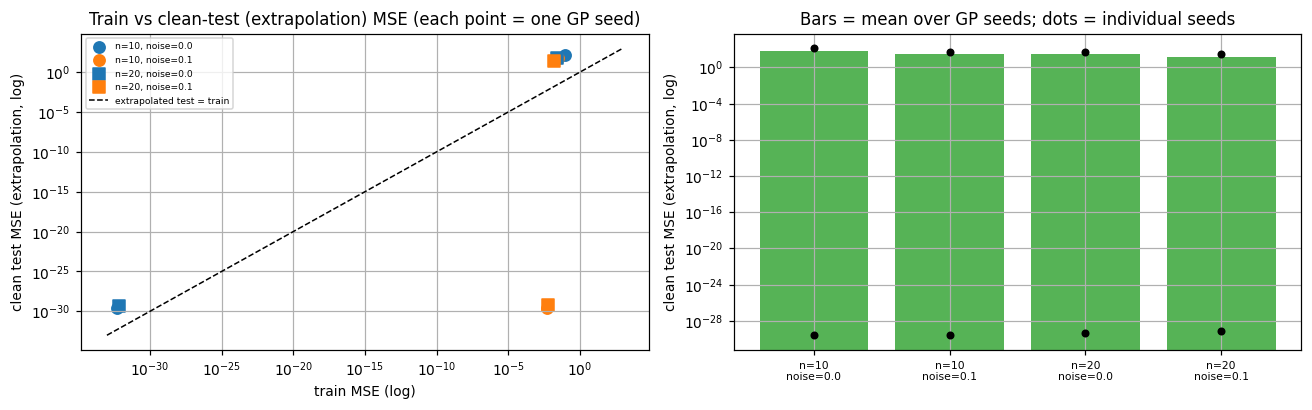

In [31]:
# E09 可视化：训练 vs 干净外推测试（log-log），以及各条件测试 MSE
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
markers = {10: "o", 20: "s"}
colors = {0.0: "tab:blue", 0.1: "tab:orange"}
for n_train in E09_N_TRAIN:
    for noise_ratio in E09_NOISE_RATIOS:
        subset = [r for r in e09_rows if r["n_train"] == n_train and r["noise"] == noise_ratio]
        axes[0].scatter([max(r["train"], 1e-33) for r in subset],
                        [max(r["test"], 1e-33) for r in subset],
                        marker=markers[n_train], color=colors[noise_ratio], s=55,
                        label=f"n={n_train}, noise={noise_ratio}")
lower = 1e-33
axes[0].plot([lower, 1e3], [lower, 1e3], "k--", lw=1, label="extrapolated test = train")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("train MSE (log)")
axes[0].set_ylabel("clean test MSE (extrapolation, log)")
axes[0].set_title("Train vs clean-test (extrapolation) MSE (each point = one GP seed)")
axes[0].legend(fontsize=6)

positions = np.arange(len(conditions))
means = [np.mean([r["test"] for r in subset]) for _, _, subset in conditions]
axes[1].bar(positions, [max(v, 1e-33) for v in means], color="tab:green", alpha=0.8)
for position, (_, _, subset) in zip(positions, conditions):
    axes[1].scatter([position] * len(subset), [max(r["test"], 1e-33) for r in subset],
                    color="black", s=18, zorder=3)
axes[1].set_yscale("log")
axes[1].set_xticks(positions)
axes[1].set_xticklabels([f"n={n}\nnoise={noise}" for n, noise, _ in conditions], fontsize=7)
axes[1].set_ylabel("clean test MSE (extrapolation, log)")
axes[1].set_title("Bars = mean over GP seeds; dots = individual seeds")
fig.tight_layout()

### 观察与解释（请填写）

> **观察与解释（请填写）**：噪声为 0.1 时训练 MSE 的下限是否接近 $\sigma^2$？
> 样本量从 20 减到 10 对外推测试 MSE 有什么影响？有没有“训练 MSE 很低但外推测试 MSE
> 很高”的过拟合迹象？训练-外推差距在哪个条件下最大？两个 GP 种子的结论一致吗？
> 用验证集选出的是哪个配置，它的外推表现如何？如果改用测试集来选择，会引入什么偏差？

**本章诚实性说明**：

- 训练/验证/测试的 x 区间互不重叠；测试标签始终干净；
- 测试区间 $[1.5,2.0]$ 在训练区间 $[-1,0.9]$ 之外，故报告的是**外推误差**，不是 i.i.d. 泛化误差；
- 测试集没有参与搜索、调参或种子挑选；
- 噪声由 `data_seed=7` 固定，GP 搜索种子另行指定（1, 2），两者分离；
- 每个条件只有 2 个 GP 种子，结论只适用于本次观察，不外推为普遍规律。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## Chapter 10：搜索空间与数值语义的限制

**核心问题**：目标是否“可表达”与有限预算下能否搜到是同一件事吗？保护除法与数值异常怎样改变语义？

### 概念与数学定义

**可达性**：给定函数集 $F$、终止符集 $T$ 与深度上限，所有合法表达式构成搜索空间
$\mathcal{S}(F,T,D)$。目标 $f$ 可达当且仅当 $\exists T\in\mathcal{S},\ T(x)=f(x)$
在讨论的定义域上成立。

**表达力 vs 可搜索性**：这是两个独立问题。

- $f$ 可表达，不代表有限预算内能搜到（搜索效率问题）；
- 有限样本上拟合得好，不代表 $f$ 可精确表达（近似问题）。

例：$\sin(x)$ **不是有理函数**（数学事实），而 $\{+,-,*,/\}$ 与 $x$ 生成的表达式都是有理
函数，因此不存在能精确表示 $\sin$ 的有限表达式树。可是 GP 仍然可能在 20 个训练点上
得到很小的 MSE——那是数值近似，不是“恢复了 sin 的公式”。

**常数表示困难**：本项目终止符只有 $x$，没有随机常数；$1=x/x$、$0=x-x$、$1/2=1/(1+1)$
等只能靠结构合成。系数搜索因此变成结构搜索的一部分，代价更高。

**保护除法与数值语义**：

$$p\_div(a,b)=\begin{cases}1.0,& b=0\\ a/b,& b\neq0\end{cases}$$

- 分母精确为 0：直接返回 1.0，**改变**了数学语义；
- 分母接近 0：做普通除法，可能得到极大值，放大数值误差；
- 深树/极端输入可能溢出为 `inf`；`fitness` 对非有限预测返回 `inf`（明确策略）。

因此标准代数化简（如 $\frac{x^2-1}{x-1}=x+1$）在保护除法下**不是全域等价**：
在 $x=1$ 处左边按保护除法得 1.0，右边是 2。

### 具体小例子

`(/ (- (* x x) (/ x x)) (- x (/ x x)))` 在 $x=1$ 处：分子 $1-1=0$，分母 $1-1=0$，
保护除法返回 1.0；而 $x+1=2$。同一条“代数恒等式”在 $x\neq1$ 时成立，在 $x=1$ 处失效。

### 源码入口

- 保护除法与求值：`gptoy/operators.py` → `p_div`、`evaluate`、`fitness`
- 自定义目标数据：`gptoy/data.py` → `make_target_data`
- 用自定义数据训练：`run_gp(config, data=...)`
- 非有限值策略：`gptoy/operators.py` → `NON_FINITE_FITNESS`（`inf`）

### E10：空间不匹配与数值语义

**研究问题**：

- A：目标含 $\sin$ 而算子集只有四则运算时，GP 会得到什么？低训练 MSE 能否证明结构恢复？
- B：保护除法在除零点、近零分母与溢出时分别表现如何？哪些代数化简会失效？

**核心概念**：可达性、算子集限制、表达力 vs 可搜索性、常数表示、保护除法、数值不稳定。

**可修改配置**（改下面单元顶部变量后重跑）：

- `E10_SIN_CFG` 的种群/代数/深度；
- `E10_PROBES`：数值语义检查的输入点（含 0、近零、正常值）。

**运行入口**：接下来两个代码单元（`# E10-A`、`# E10-B`）。

**源码位置**：`make_target_data`、`p_div`、`fitness`。

> **我的预测（请填写）**：四则运算 GP 在 sin 的 20 个训练点上能到多小的 MSE？
> 它的测试 MSE 会小吗？（提示：sin 在 $[1,2]$ 上的形状与 $[-1,1]$ 很不同。）它学到的
> 表达式大致是什么样子？保护除法在 $x=0$ 与 $x=10^{-320}$ 处分别会返回什么？

In [32]:
# E10-A 目标含 sin，但算子集只有 {+,-,*,/} 与 x
E10_SIN_CFG = replace(cfg, seed=0, population_size=40, max_generations=15,
                      max_tree_depth=9, stop_on_target=False)
data_sin = make_target_data(np.sin, n_train=20, train_range=(-1.0, 1.0),
                            n_test=10, test_range=(1.0, 2.0))
e10_sin = run_gp(E10_SIN_CFG, data=data_sin)

print_table(
    ["指标", "数值"],
    [
        ("训练 MSE（sin, 20 点）", f"{e10_sin.train_mse:.4e}"),
        ("测试 MSE（sin, [1,2] 10 点）", f"{e10_sin.test_mse:.4e}"),
        ("best 表达式", e10_sin.best_of_run.sexpr_str()),
        ("size / depth", f"{e10_sin.best_of_run.size()} / {e10_sin.best_of_run.depth()}"),
        ("evaluations", e10_sin.evaluations),
    ],
)
print()
print("sin 不是有理函数，因此不存在能精确表示它的有限四则运算表达式；")
print("上面的训练 MSE 无论多小，都只能是有限样本上的数值近似。")

指标                          数值                                                                                 
----------------------------  -------------------------------------------------------------------------------------
训练 MSE（sin, 20 点）        4.8721e-03                                                                           
测试 MSE（sin, [1,2] 10 点）  3.9557e-01                                                                           
best 表达式                   (/ (* (* (/ x x) x) (/ (/ x x) (+ x x))) (/ (/ (+ x x) (- x x)) (+ (+ x x) (- x x))))
size / depth                  29 / 5                                                                               
evaluations                   640                                                                                  

sin 不是有理函数，因此不存在能精确表示它的有限四则运算表达式；
上面的训练 MSE 无论多小，都只能是有限样本上的数值近似。


在 [-2,2] 上 |learned - sin| 的中位数 = 0.1597
训练区间 [-1,1] 上的最大绝对误差 = 0.1585


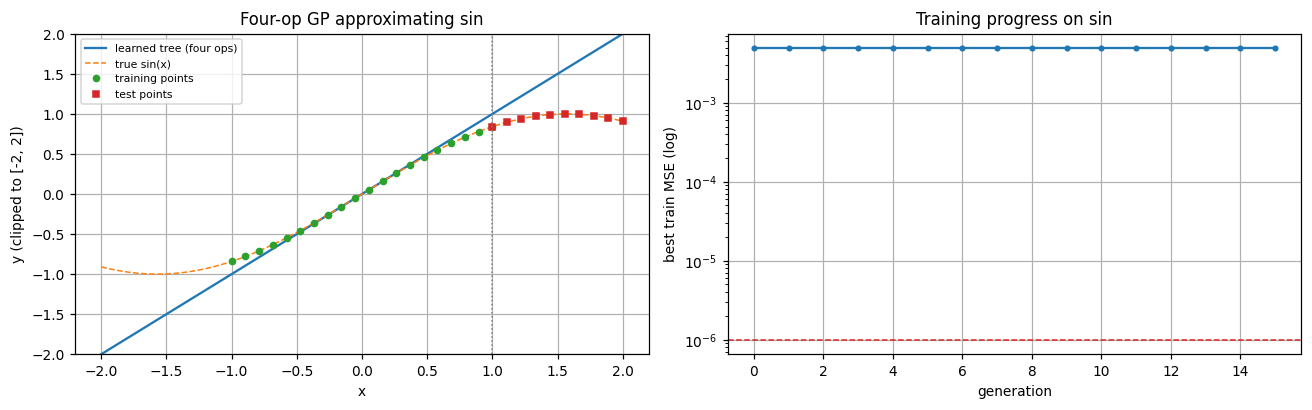

In [33]:
# E10-A 可视化：学到的函数 vs sin（注意纵轴范围被截断以便观察）
xs_dense = np.linspace(-2.0, 2.0, 400)
learned = evaluate(e10_sin.best_of_run, xs_dense)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(xs_dense, learned, label="learned tree (four ops)")
axes[0].plot(xs_dense, np.sin(xs_dense), "--", lw=1, label="true sin(x)")
axes[0].plot(data_sin[0], data_sin[1], "o", ms=4, label="training points")
axes[0].plot(data_sin[2], data_sin[3], "s", ms=4, label="test points")
axes[0].axvline(1.0, color="gray", ls=":", lw=1)
axes[0].set_ylim(-2.0, 2.0)
axes[0].set_xlabel("x")
axes[0].set_ylabel("y (clipped to [-2, 2])")
axes[0].set_title("Four-op GP approximating sin")
axes[0].legend(fontsize=7)

axes[1].semilogy(e10_sin.best_mse_history, "-o", ms=3)
axes[1].axhline(E10_SIN_CFG.mse_target, color="tab:red", ls="--", lw=1)
axes[1].set_xlabel("generation")
axes[1].set_ylabel("best train MSE (log)")
axes[1].set_title("Training progress on sin")
fig.tight_layout()

print(f"在 [-2,2] 上 |learned - sin| 的中位数 = {np.median(np.abs(learned - np.sin(xs_dense))):.4g}")
print(f"训练区间 [-1,1] 上的最大绝对误差 = {np.max(np.abs(evaluate(e10_sin.best_of_run, np.linspace(-1,1,200)) - np.sin(np.linspace(-1,1,200)))):.4g}")

In [34]:
# E10-B 保护除法的数值语义：除零点、近零分母、溢出
E10_PROBES = (0.0, 1e-320, 1e-12, 1.0, 2.0)
expressions = {
    "x/x": "(/ x x)",
    "(x-x)/x": "(/ (- x x) x)",
    "1/x（由 (x/x)/x 合成）": "(/ (/ x x) x)",
    "(x^2-1)/(x-1)": "(/ (- (* x x) (/ x x)) (- x (/ x x)))",
}
rows = []
for name, sexpr in expressions.items():
    tree = str_to_tree(sexpr, cfg)
    values = [evaluate(tree, v) for v in E10_PROBES]
    rows.append((name, *[f"{v:.6g}" for v in values]))
print_table(["表达式"] + [f"x={v:g}" for v in E10_PROBES], rows)
print()
ratio_tree = str_to_tree(expressions["(x^2-1)/(x-1)"], cfg)
print("代数恒等式 (x^2-1)/(x-1) = x+1 的检验：")
print_table(
    ["x", "保护除法结果", "x+1", "是否相等"],
    [(f"{v:g}", f"{evaluate(ratio_tree, v):.6g}", f"{v + 1:.6g}",
      "是" if abs(evaluate(ratio_tree, v) - (v + 1)) < 1e-9 else "**否**")
     for v in (0.5, 1.0, 2.0)],
)
print()
overflow_tree = str_to_tree("(/ (/ x x) x)", cfg)
probe = np.array([1e-320])
print(f"溢出检查：evaluate 在 x=1e-320 处 = {evaluate(overflow_tree, 1e-320)}")
print(f"fitness 对非有限预测的策略：{fitness(overflow_tree, probe, np.array([0.0]))}（NON_FINITE_FITNESS = inf）")
print("说明：非有限值被判为最差个体，不会以 NaN 形式污染选择比较。")

表达式                  x=0  x=9.99989e-321  x=1e-12  x=1  x=2
----------------------  ---  --------------  -------  ---  ---
x/x                     1    1               1        1    1  
(x-x)/x                 1    0               0        0    0  
1/x（由 (x/x)/x 合成）  1    inf             1e+12    1    0.5
(x^2-1)/(x-1)           1    1               1        1    3  

代数恒等式 (x^2-1)/(x-1) = x+1 的检验：
x    保护除法结果  x+1  是否相等
---  ------------  ---  --------
0.5  1.5           1.5  是      
1    1             2    **否**  
2    3             3    是      

溢出检查：evaluate 在 x=1e-320 处 = inf
fitness 对非有限预测的策略：inf（NON_FINITE_FITNESS = inf）
说明：非有限值被判为最差个体，不会以 NaN 形式污染选择比较。


### 观察与解释（请填写）

> **观察与解释（请填写）**：sin 实验的训练/测试 MSE 差多少？表达式是否呈现出对训练区间的
> 近似而非 sin 的结构？（你无法从表达式直接看出 sin，因为 sin 不可达。）
> 保护除法在 $x=0$ 与 $x=10^{-320}$ 处分别返回什么？哪一条代数恒等式失效？
> 如果把非有限值策略改成“返回一个很大的有限数”，选择行为可能怎样变化？请写下猜测
> 并标注为猜测。

**本章诚实性说明**：

- “sin 不可用有限四则运算精确表示”是数学事实（sin 不是有理函数），不是本次实验的观察；
- 训练 MSE 小只说明 20 个点上的数值近似，不构成结构恢复；
- 非有限值策略是**有意加入**的显式策略：默认 seed=3 的 Koza-1 轨迹经测试未受影响，
  只有在出现溢出/NaN 的病态个体时才会改变行为（见 README）。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

# 第三篇：从实验走向研究

*Chapter 11：把观察组织成可检验的失败机制与改进方向*

> 本部分包含：Chapter 11 GP 失败机制与改进方法

## Chapter 11：GP 失败机制与改进方法

> 第三篇导言：本部分把 Chapter 0–10 的观察组织成可检验的失败机制与改进方向。

**核心问题**：如何把观察到的失败现象组织成可检验的机制解释？前人可能的改进分别针对哪些机制？

本章不引入新算法，而是把 Chapter 0–10 的观察整理成一张**失败分类表**。每一行都包含：
机制假设、可观察指标、支持/反对证据、尚不能区分的替代解释、可调研的改进方向。
请把它当作“研究问题生成器”，而不是结论清单。

### 概念与数学定义

**失败机制**：一个可检验的因果陈述，说明“在什么条件下、哪个环节、通过什么过程”导致
可观察的失败现象。它必须能推出**可区分的预测**，例如“若多样性耗尽是主因，则在相同预算下
降低选择压力应提高达标率；若预算不足是主因，则降低选择压力收益有限而增加预算收益显著”。

**失败分类的评价标准**：

- 机制是否明确到可以控制变量？
- 指标是否可观察、可复现（与种子/配置绑定）？
- 证据是“观察”“对照实验”还是“猜测”？
- 是否存在同样能解释现象的替代机制？

### 具体小例子

本次 Notebook 的一个真实模式：小预算（E07，5 代）下有些种子训练 MSE 停在 $10^{-2}$ 量级，
同时（E08-A）不同 k 的多样性曲线不同。仅凭这两点还不能断言“选择压力导致失败”，因为
“预算不足”也能解释停滞。可检验的做法是：固定预算、只改 k，比较达标率；再固定 k、只改预算，
比较达标率。**两种变化都有效，才说明两个机制都在起作用**（这仍是本次样本内的结论）。

### 失败分类表（7 类）

| 失败类型 | 可能的机制解释 | 可观察指标 | 本次实验中的支持/反对证据 | 尚不能区分的替代解释 | 可调研的改进方向 |
|---|---|---|---|---|---|
| 1. 搜索效率不足 | 预算内触及不到可达的好结构；初始化/算子覆盖不足 | 首达代、评估次数、失败种子的 best MSE 平台 | E07：预算 5→15 时训练达标率变化；仍有失败种子 | 预算仍太小 / 搜索空间结构本身难达 / 选择效率低 | 更大预算、更强初始化、局部搜索（如常数优化）、并行多种子 |
| 2. 多样性丧失与搜索停滞 | 选择压力过强、精英/复制过多，种群结构趋同 | `unique_ratio`、`fitness_std`、best MSE 平台长度 | E08-A：不同 k 的多样性曲线可比较；是否停滞需看曲线 | 收敛到正确解也会降多样性 / 种群规模太小 / 变异破坏性太强 | 小生境、物种形成、自适应变异率、年龄分层 |
| 3. 表达式复杂度膨胀 | 选择间接奖励规模；中性/寄生结构累积 | `mean_size`、`max_size` 随代增长 vs best MSE 改善 | E08-A/B：规模曲线与原始 MSE 可对照；本实验未必出现膨胀 | 预算不足导致未及膨胀 / 深度上限截断 / 目标本身需要更复杂结构 | 简约压力、尺寸上限、多目标（Pareto）、结构重用惩罚 |
| 4. 噪声与过拟合 | 目标利用训练噪声；小样本欠定 | 训练 vs 验证/测试 MSE 差、最终复杂度 | E09：不同噪声/样本量下的 train/val/clean-test 对照 | 可能是欠拟合而非过拟合 / 小预算导致两者都差 / 噪声尺度定义影响 | 正则化、验证集早停、数据增强、集成/多目标 |
| 5. 表达式空间限制 | 函数集/终止符集无法表达目标；深度上限截断 | 训练 MSE 平台、表达式结构检查、目标是否可达的数学论证 | E10-A：sin 不可达，训练 MSE 再低也只是近似 | 也许是可表达但难搜索 / 采样点太少 / 保护运算改变语义 | 扩充算子集（sin/exp/log）、加入常数、元语法/强类型 GP |
| 6. 常数优化困难 | 无随机常数；系数只能结构合成，搜索代价高 | 需要常数系数的目标上的收敛速度、表达式冗长程度 | Chapter 0：目标需要合成 1；E07/E08 的表达式常含 `(/ x x)` 等常数构造 | 也可能是算子集过窄 / 选择压力不足 | 常数注册与随机扰动、最小二乘系数优化、两阶段搜索 |
| 7. 评价指标与模型选择问题 | 用训练/测试 MSE 代表“恢复”；用测试集调参或挑种子 | 报告口径、种子集合、是否只看最好种子、结构恢复率是否缺失 | E03：0 训练误差的多个结构；E07：训练/测试达标率分离；Chapter 0：数值一致但结构不同 | 也许 MSE 已足以服务预测任务（若目标只是预测） | 结构判别/等价类检验、独立验证集选择、预注册种子与指标、报告全部种子 |

### 如何区分“观察 / 机制 / 猜测 / 文献”

| 层级 | 写法示例 | 需要什么证据 |
|---|---|---|
| 观察 | “预算 5 代时 6 个种子中 2 个训练达标” | 运行记录、种子、配置 |
| 机制解释 | “关闭提前停止后仍失败，说明不是提前停止造成的” | 至少一个控制了关键变量的对照实验 |
| 猜测 | “我猜是种群多样性太低导致” | 尚未检验；必须标注猜测并写出可检验预测 |
| 数学事实/文献 | “sin 不是有理函数，所以不可精确表示” | 数学证明或可引用来源 |

### 研究问题模板

一个可检验的问题应包含：**现象** + **机制候选** + **可区分预测**。例如：

> 现象：小预算下失败种子的 best MSE 停在 $10^{-2}$ 附近。
> 机制候选 A：预算不足；B：选择压力过强导致多样性耗尽。
> 可区分预测：若 A 成立，增加预算应显著提高达标率且多样性下降更慢；若 B 成立，在相同预算下
> 降低 k 应提高达标率，而单纯增加预算收益有限。→ 用 E07/E08 的组合实验检验。

### 源码入口

本章不需要新源码；请回看 `gptoy/metrics.py`（可观察指标）、`gptoy/tracing.py`（逐代证据）、
`gptoy/experiments.py`（对照实验与保存）以及各章源码入口。

### 综合复盘：把前面实验的真实数字拼起来

**研究问题**：在同一份 Notebook 运行中，各章实验的结果能否支持或反驳失败分类表中的某些行？
哪些结论只是本次运行的观察，哪些还缺对照？

**运行入口**：下一代码单元（`# E11`）只读取前面实验的真实结果对象，不重新运行算法、
不硬编码任何数字。

> **我的预测（请填写）**：把 E07（预算）、E08（选择压力/复杂度）、E09（噪声/样本）、
> E10（空间）的结果放在一起，你认为本次运行最主要的失败类型是哪一类？你准备用哪个
> 可区分预测去检验它？

In [35]:
# E11 综合复盘：读取前面实验的真实结果，生成一张“证据卡”
evidence_rows = []
for budget, results in e07_results.items():
    summary = summarize_runs(results)
    evidence_rows.append((f"E07 budget={budget}", f"train={summary['train_success_rate']:.2f}",
                          f"test={summary['test_success_rate']:.2f}",
                          f"hits={summary['first_hit_generation']['values']}"))
for k, runs in e08a.items():
    last = [r.snapshots[-1] for r in runs]
    evidence_rows.append((f"E08-A k={k}", f"train={np.mean([r.train_mse for r in runs]):.3g}",
                          f"unique={np.mean([s.unique_ratio for s in last]):.2f}",
                          f"mean_size={np.mean([s.mean_size for s in last]):.1f}"))
for name, r in e08b.items():
    evidence_rows.append((f"E08-B {name}", f"train={r.train_mse:.3g}",
                          f"size={r.best_of_run.size()}",
                          f"mean_size(last)={r.snapshots[-1].mean_size:.1f}"))
for n_train, noise, subset in conditions:
    evidence_rows.append((f"E09 n={n_train},noise={noise}",
                          f"train={np.mean([r['train'] for r in subset]):.3g}",
                          f"val={np.mean([r['val'] for r in subset]):.3g}",
                          f"clean_test={np.mean([r['test'] for r in subset]):.3g}"))
evidence_rows.append(("E10-A sin", f"train={e10_sin.train_mse:.3g}",
                      f"test={e10_sin.test_mse:.3g}",
                      f"size={e10_sin.best_of_run.size()}"))
print_table(["实验/条件", "指标 1", "指标 2", "指标 3"], evidence_rows)

实验/条件             指标 1          指标 2       指标 3              
--------------------  --------------  -----------  --------------------
E07 budget=5          train=0.33      test=0.33    hits=[3, 4]         
E07 budget=15         train=0.67      test=0.67    hits=[3, 7, 4, 12]  
E08-A k=1             train=0.0121    unique=0.88  mean_size=67.3      
E08-A k=7             train=0.0211    unique=0.70  mean_size=27.2      
E08-A k=12            train=4.71e-32  unique=0.68  mean_size=33.3      
E08-B depth<=5        train=5.32e-32  size=15      mean_size(last)=14.6
E08-B depth<=9        train=6.47e-33  size=31      mean_size(last)=32.3
E08-B MSE+0.001*size  train=0.0241    size=19      mean_size(last)=24.2
E08-B MSE+0.01*size   train=0.0241    size=15      mean_size(last)=21.2
E09 n=10,noise=0.0    train=0.0483    val=1.44     clean_test=64.2     
E09 n=10,noise=0.1    train=0.018     val=0.47     clean_test=27.2     
E09 n=20,noise=0.0    train=0.0127    val=0.47     clean_test=27.2     
E0

In [36]:
# E11 失败诊断卡：挑一个真实失败种子（按训练 MSE，不按测试挑选），打印可观察指标
worst_run = max(e07_results[min(E07_BUDGETS)], key=lambda r: r.train_mse)
last = worst_run.snapshots[-1]
print("失败诊断卡（来自 E07 最小预算组的训练最差种子）：")
print_table(
    ["字段", "值"],
    [
        ("seed", worst_run.seed),
        ("stop_reason", worst_run.stop_reason),
        ("generations / evaluations", f"{worst_run.n_generations} / {worst_run.evaluations}"),
        ("final train MSE", f"{worst_run.train_mse:.4e}"),
        ("final test MSE", f"{worst_run.test_mse:.4e}"),
        ("best 表达式", worst_run.best_of_run.sexpr_str()),
        ("size / depth", f"{worst_run.best_of_run.size()} / {worst_run.best_of_run.depth()}"),
        ("last unique_ratio", f"{last.unique_ratio:.3f}"),
        ("last fitness_std", f"{last.fitness_std:.4g}"),
        ("mean_size / max_size", f"{last.mean_size:.1f} / {last.max_size}"),
        ("best train MSE 轨迹", [f"{v:.3g}" for v in worst_run.best_mse_history]),
    ],
)
print()
print("这不是自动结论。请回答：这张卡能支持失败分类表中的哪几行？")
print("要区分这些行，你下一步会控制哪个变量、预期看到什么差异？")

失败诊断卡（来自 E07 最小预算组的训练最差种子）：
字段                       值                                                                                                     
-------------------------  -------------------------------------------------------------------------------------------------------
seed                       1                                                                                                      
stop_reason                max_generations                                                                                        
generations / evaluations  5 / 240                                                                                                
final train MSE            7.6896e-02                                                                                             
final test MSE             7.1936e+01                                                                                             
best 表达式                (+ x (+ (* (+ (* x x) x) (+ x x)) 

### 观察与解释（请填写）

> **观察与解释（请填写）**：综合表里哪些数字支持“搜索效率不足”？哪些支持“多样性丧失”？
> 哪些行在本次运行中**没有**得到支持（例如没有观察到膨胀）？失败诊断卡里最可疑的指标是哪个？
> 请写出一个包含“现象 + 机制候选 + 可区分预测”的研究问题，并说明你还需要补哪个实验。

### 解释与局限

- 这张分类表是**启发式组织方式**，不是互斥的完备分类；同一现象常有多类机制同时作用；
- 表中的“支持证据”只来自本 Notebook 的小规模实验，不能当作普遍结论；
- 未实现神经 GP/现代符号回归框架，因此“改进方向”只到可调研的问题层面，不代表已验证有效；
- 外部文献结论在本章没有引用具体论文；若你补充文献，请注明来源并与本次观察分开记录。

### 本章笔记（请填写）

**1. 核心概念（用自己的话重述）**

> 待填写

**2. 实现机制与源码位置**

> 待填写

**3. 我的实验问题与预测**

> 待填写

**4. 实验配置及观察结果**

> 待填写

**5. 我的理解、替代解释与证据边界**

> 待填写

**6. 本章总结与后续问题**

> 待填写

## 附录 A：保存实验结果、放大规模与保存笔记

### A.1 保存可独立读取的实验结果

下面的代码把 E07 的最小预算组保存为 JSON（配置、种子、全部结果、摘要）。文件写在
`results/` 下，该目录被 `.gitignore` 忽略，不会污染代码仓库。

> 注意：这类生成物只保存很小、可复现的聚合结果；不要提交大型输出。

In [37]:
# 保存 E07 小预算组：配置 + 种子 + 全部结果 + 摘要
from pathlib import Path

e07_small_budget = min(E07_BUDGETS)
e07_small_summary = summarize_runs(e07_results[e07_small_budget])
e07_save_path = save_experiment(
    Path(ROOT) / "results" / "lab_e07_small_budget.json",
    e07_base, e07_results[e07_small_budget], e07_small_summary,
)
payload = load_experiment(e07_save_path)
print(f"已写入：{e07_save_path.resolve()}")
print(f"文件大小：{e07_save_path.stat().st_size} bytes")
print(f"顶层键：{sorted(payload)}")
print(f"种子：{payload['seeds']}")
print(f"结果条数：{len(payload['results'])}；摘要 n_runs：{payload['summary']['n_runs']}")

已写入：G:\CreateMyself\others\ReproducePaper\GP\.dsh-best-of-3\gptoy-lab-20261022-2e22987\candidates\a\results\lab_e07_small_budget.json
文件大小：31868 bytes
顶层键：['config', 'format_version', 'results', 'saved_at', 'seeds', 'summary']
种子：[0, 1, 2, 3, 4, 5]
结果条数：6；摘要 n_runs：6


### A.2 放大实验规模

默认配置刻意很小，便于几十秒内跑完全部实验。若要得到更稳定的统计结论，请按下面的方式放大，
并注意“先声明种子与指标，再看结果”：

| 目标 | 建议改动 | 代价与注意 |
|---|---|---|
| 复现 Koza-1 成功案例 | 直接使用 `GPConfig(seed=3)`（种群 100、50 代） | 单次约 1 秒；seed=3 是旧版搜索出的教学种子 |
| 多种子成功率 | `E07_SEEDS = range(20)`、`E07_BUDGETS = (10, 25, 50)` | 运行时间线性增长；仍只报告全部种子 |
| 选择压力对照 | `E08A_KS = (1, 3, 7, 15)`、`E08A_SEEDS = range(5)` | 每个 k×seed 一次完整运行 |
| 复杂度/噪声对照 | 增加 `E08B_LAMBDAS`、`E09_GP_SEEDS` | 简约惩罚 λ 越大，原始 MSE 通常越差，需同时报告两者 |
| 更大搜索空间 | `GPConfig(max_tree_depth=17, population_size=100, max_generations=50)` | 深树可能极慢（膨胀），务必先小预算试跑 |

放大时请保持：**测试集不参与选择**；**先固定种子集合**；**报告全部结果与失败案例**；
**把结构恢复与数值拟合分开**。

### A.3 保存个人笔记

- 直接在 Notebook 的“本章笔记”单元里填写 Markdown，然后 `Ctrl+S` 保存 `.ipynb`；
- 也可以把结论同步到 `notes/GP_learning_notes.md`（与 Notebook 章节一一对应）；
- **注意**：`scripts/build_learning_lab.py` 会重新生成 Notebook 与笔记骨架。为避免覆盖
  已填写的个人内容，脚本在目标文件已存在时默认**拒绝写入**；只有在明确传入 `--force`
  时才会覆盖。请先备份你的笔记。

### A.4 常见问题

| 问题 | 处理 |
|---|---|
| `ModuleNotFoundError: gptoy` | 确认 kernel 为 `gptoy`，或在仓库根目录启动 Jupyter；第一个代码单元会把仓库根加入 `sys.path` |
| 图不显示 | 确认已运行第一个代码单元的 `%matplotlib inline`；无头执行时设置 `MPLBACKEND=Agg` |
| 运行很慢 / 内存升高 | 深树膨胀会使求值代价急剧上升；先降低 `max_tree_depth` 或 `max_generations` |
| 结果与上次不同 | 检查 `seed` 是否固定；`data_seed` 与 GP `seed` 是两个独立随机源 |
| 想清空输出重新运行 | Jupyter: Kernel → Restart & Run All |